# 1. Experiment Overview: MFMP Final Reproducible Experiment

- Hyperparameter and MFMP threshold-range selection use one fixed 10-fold stratified cross-validation on TRAIN.
- Every candidate is evaluated with the classifier's fixed default decision threshold: 0.5 for LR/RF and 0 for Linear SVM.
- Candidate configurations are selected by mean validation Macro-F1, then mean F1-Sarcasm, mean Recall-Sarcasm, and mean Accuracy.
- AP, PR-AUC, and ROC-AUC remain threshold-independent diagnostic metrics only and never drive C, K, RF-parameter, or representation selection.
- After each best CLS/Mean/MFMP configuration is fixed, pooled 10-fold OOF TRAIN scores are generated for that configuration only and used to select the final operating threshold by Macro-F1, then F1-Sarcasm, Recall-Sarcasm, and Accuracy.

This notebook implements the final, leakage-safe, reproducible comparison of **CLS Pooling**, **Mean Pooling**, and the proposed **Magnitude-Filtered Mean Pooling (MFMP)** using a frozen local **MARBERTv2** encoder and three classical classifiers: Logistic Regression, Linear SVM, and Random Forest.

Scientific protocol enforced here:
- Official `train.csv` / `test.csv` split is preserved exactly.
- Test data is never used for K selection, hyperparameter selection, or threshold selection.
- MARBERTv2 is used only as a frozen contextual feature extractor.
- A single encoder pass per dataset produces CLS, Mean, and all 40 MFMP representations.
- Final TEST evaluation uses configurations frozen from TRAIN.

## 2. Imports

In [1]:
from __future__ import annotations

import gc
import hashlib
import itertools
import json
import logging
import math
import os
import platform
import random
import sys
from dataclasses import dataclass
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Dict, Iterable, List, Optional, Tuple

import matplotlib.pyplot as plt
import openpyxl
import numpy as np
import pandas as pd
import sklearn
import torch
import transformers
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    auc,
    average_precision_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    confusion_matrix,
    matthews_corrcoef,
    precision_recall_curve,
    precision_recall_fscore_support,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import ParameterGrid, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from tqdm.auto import tqdm
from transformers import AutoModel, AutoTokenizer

<PYTHON_ENV>\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 3. Configuration

In [3]:
# =========================
# EDITABLE EXPERIMENT CONFIG
# =========================
RANDOM_SEED = 42
MAX_LEN = 320
BATCH_SIZE = 32
CV_FOLDS = 10

K_UPPER_VALUES = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
K_LOWER_VALUES = [0.0001, 0.001, 0.01]

LR_C_VALUES = [ 0.001, 0.0001]
SVM_C_VALUES = [0.001, 0.0001]

RF_PARAM_GRID = {
    "n_estimators": [400],
    "max_depth": [None, 30],
    "min_samples_split": [2],
    "min_samples_leaf": [2],
    "max_features": ["sqrt"],
    "class_weight": ["balanced_subsample"],
}

TEXT_COLUMN = "clean_keep"
LABEL_COLUMN = "sarcasm"
EPSILON = 1e-12
REPRESENTATION_DTYPE = np.float32

# Automatically locate project root whether launched from project root or notebooks/.
def discover_project_root(start: Path) -> Path:
    start = start.resolve()
    candidates = [start] + list(start.parents)
    for candidate in candidates:
        if (candidate / "data" / "processed" / "train.csv").exists() and (candidate / "models" / "MARBERTv2").exists():
            return candidate
    # Common case when notebook lives in notebooks/ but CWD differs.
    notebook_parent = start / "notebooks"
    if notebook_parent.exists() and (start / "data" / "processed" / "train.csv").exists():
        return start
    raise FileNotFoundError(
        "Could not discover PROJECT_ROOT. Expected data/processed/train.csv and models/MARBERTv2 under the project root."
    )

PROJECT_ROOT = discover_project_root(Path.cwd())
TRAIN_PATH = PROJECT_ROOT / "data" / "processed" / "train.csv"
TEST_PATH = PROJECT_ROOT / "data" / "processed" / "test.csv"
MODEL_PATH = PROJECT_ROOT / "models" / "MARBERTv2"
OUTPUT_DIR = PROJECT_ROOT / "experiments" / "MFMP_Final_Experiment"

CONFIG_DIR = OUTPUT_DIR / "config"
METRICS_DIR = OUTPUT_DIR / "metrics"
PREDICTIONS_DIR = OUTPUT_DIR / "predictions"
PLOTS_DIR = OUTPUT_DIR / "plots"
LOGS_DIR = OUTPUT_DIR / "logs"
CACHE_DIR = OUTPUT_DIR / "cache"
TABLES_DIR = OUTPUT_DIR / "tables"

ALL_OUTPUT_DIRS = [CONFIG_DIR, METRICS_DIR, PREDICTIONS_DIR, PLOTS_DIR, LOGS_DIR, CACHE_DIR, TABLES_DIR]
for directory in ALL_OUTPUT_DIRS:
    directory.mkdir(parents=True, exist_ok=True)

K_CONFIGS = [(kl, ku) for kl in K_LOWER_VALUES for ku in K_UPPER_VALUES if kl <= ku]
assert len(K_CONFIGS) == 30, f"Expected 30 MFMP K configurations, found {len(K_CONFIGS)}"

RF_COMBINATIONS = list(ParameterGrid(RF_PARAM_GRID))
print(f"PROJECT_ROOT: {PROJECT_ROOT}")
print(f"MFMP configurations: {len(K_CONFIGS)}")
print(f"RF parameter combinations: {len(RF_COMBINATIONS)}")

PROJECT_ROOT: <PROJECT_ROOT>
MFMP configurations: 30
RF parameter combinations: 2


## 4. Reproducibility

In [4]:
def set_global_seed(seed: int) -> None:
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    try:
        torch.use_deterministic_algorithms(True, warn_only=True)
    except Exception:
        pass

set_global_seed(RANDOM_SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None

# Resolve LinearSVC dual setting safely and record it.
def resolve_linear_svc_dual() -> Any:
    X_probe = np.array([[0.0, 0.0], [1.0, 1.0], [0.0, 1.0], [1.0, 0.0]], dtype=np.float64)
    y_probe = np.array([0, 1, 0, 1], dtype=np.int64)
    try:
        LinearSVC(C=1.0, dual="auto", max_iter=100, random_state=RANDOM_SEED).fit(X_probe, y_probe)
        return "auto"
    except Exception:
        # n_samples >> n_features in this experiment; primal optimization is appropriate.
        return False

SVM_DUAL_SETTING = resolve_linear_svc_dual()

ENVIRONMENT = {
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": sys.version,
    "platform": platform.platform(),
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "pytorch_version": torch.__version__,
    "transformers_version": transformers.__version__,
    "scikit_learn_version": sklearn.__version__,
    "cuda_available": bool(torch.cuda.is_available()),
    "cuda_version": torch.version.cuda,
    "gpu_name": GPU_NAME,
    "device": str(DEVICE),
    "linear_svc_dual_setting": SVM_DUAL_SETTING,
}

with open(CONFIG_DIR / "environment.json", "w", encoding="utf-8") as f:
    json.dump(ENVIRONMENT, f, indent=2, ensure_ascii=False)

display(pd.DataFrame([ENVIRONMENT]).T.rename(columns={0: "value"}))

,value
timestamp_utc,2026-09-14T00:58:35.189438+00:00
python_version,"3.10.19 | packaged by conda-forge | (main, Jan..."
platform,Windows-10-10.0.26200-SP0
numpy_version,2.2.6
pandas_version,2.3.3
pytorch_version,2.10.0+cu126
transformers_version,5.0.0
scikit_learn_version,1.7.2
cuda_available,True
cuda_version,12.6


## 5. Paths and Output Directories

In [5]:
for required_path in [TRAIN_PATH, TEST_PATH, MODEL_PATH]:
    if not required_path.exists():
        raise FileNotFoundError(f"Required project input not found: {required_path}")

EXPERIMENT_CONFIG = {
    "random_seed": RANDOM_SEED,
    "max_len": MAX_LEN,
    "batch_size": BATCH_SIZE,
    "cv_folds": CV_FOLDS,    "k_upper_values": K_UPPER_VALUES,
    "k_lower_values": K_LOWER_VALUES,
    "lr_c_values": LR_C_VALUES,
    "svm_c_values": SVM_C_VALUES,
    "rf_param_grid": RF_PARAM_GRID,
    "train_path": str(TRAIN_PATH.relative_to(PROJECT_ROOT)),
    "test_path": str(TEST_PATH.relative_to(PROJECT_ROOT)),
    "model_path": str(MODEL_PATH.relative_to(PROJECT_ROOT)),
    "output_dir": str(OUTPUT_DIR.relative_to(PROJECT_ROOT)),
    "text_column": TEXT_COLUMN,
    "label_column": LABEL_COLUMN,
    "mfmp_std_definition": "sentence-local population standard deviation (ddof=0)",
    "mfmp_filter_rule": "K_lower <= abs(z_i) <= K_upper on valid non-padding tokens",}
with open(CONFIG_DIR / "experiment_config.json", "w", encoding="utf-8") as f:
    json.dump(EXPERIMENT_CONFIG, f, indent=2, ensure_ascii=False)

print("Output directories:")
for directory in ALL_OUTPUT_DIRS:
    print(" -", directory.relative_to(PROJECT_ROOT))

Output directories:
 - experiments\MFMP_Final_Experiment\config
 - experiments\MFMP_Final_Experiment\metrics
 - experiments\MFMP_Final_Experiment\predictions
 - experiments\MFMP_Final_Experiment\plots
 - experiments\MFMP_Final_Experiment\logs
 - experiments\MFMP_Final_Experiment\cache
 - experiments\MFMP_Final_Experiment\tables


### Experiment Logging

In [6]:

# Configure a file log without overwriting old unrelated project logs.
LOGGER = logging.getLogger("MFMP_Final_Experiment")
LOGGER.setLevel(logging.INFO)
LOGGER.handlers.clear()
_file_handler = logging.FileHandler(LOGS_DIR / "experiment.log", mode="a", encoding="utf-8")
_file_handler.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))
LOGGER.addHandler(_file_handler)
LOGGER.info("MFMP Final Experiment notebook initialized")
LOGGER.info("PROJECT_ROOT=%s", PROJECT_ROOT)
LOGGER.info("DEVICE=%s", DEVICE)


## 6. Dataset Loading and Validation

In [7]:
def dataframe_fingerprint(df: pd.DataFrame, columns: List[str]) -> str:
    hashed = pd.util.hash_pandas_object(df[columns], index=True).values.tobytes()
    return hashlib.sha256(hashed).hexdigest()

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

for name, df in [("Train", train_df), ("Test", test_df)]:
    missing_required = [c for c in [TEXT_COLUMN, LABEL_COLUMN] if c not in df.columns]
    if missing_required:
        raise KeyError(f"{name} is missing required columns: {missing_required}. Available: {list(df.columns)}")

# Preserve row counts exactly: NaN text is replaced with an empty string, never dropped.
train_nan_texts = int(train_df[TEXT_COLUMN].isna().sum())
test_nan_texts = int(test_df[TEXT_COLUMN].isna().sum())
train_df[TEXT_COLUMN] = train_df[TEXT_COLUMN].fillna("").astype(str)
test_df[TEXT_COLUMN] = test_df[TEXT_COLUMN].fillna("").astype(str)

# Labels must be binary and complete.
for name, df in [("Train", train_df), ("Test", test_df)]:
    if df[LABEL_COLUMN].isna().any():
        raise ValueError(f"{name} contains missing labels in '{LABEL_COLUMN}'. The experiment cannot continue safely.")
    labels = set(pd.unique(df[LABEL_COLUMN]))
    if not labels.issubset({0, 1}):
        raise ValueError(f"{name} labels must be only 0/1; found {labels}")
    df[LABEL_COLUMN] = df[LABEL_COLUMN].astype(np.int64)

# Explicit local row IDs avoid any accidental dependence on CSV index labels.
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
train_df["row_id"] = np.arange(len(train_df), dtype=np.int64)
test_df["row_id"] = np.arange(len(test_df), dtype=np.int64)
train_df["row_key"] = "train:" + train_df["row_id"].astype(str)
test_df["row_key"] = "test:" + test_df["row_id"].astype(str)
if not set(train_df["row_key"]).isdisjoint(set(test_df["row_key"])):
    raise RuntimeError("Train/Test dataframe row keys overlap; refusing to continue.")

TRAIN_FINGERPRINT = dataframe_fingerprint(train_df, [TEXT_COLUMN, LABEL_COLUMN])
TEST_FINGERPRINT = dataframe_fingerprint(test_df, [TEXT_COLUMN, LABEL_COLUMN])

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Train columns:", list(train_df.columns))
print("Test columns:", list(test_df.columns))
print("\nMissing values (Train):\n", train_df.isna().sum())
print("\nMissing values (Test):\n", test_df.isna().sum())
print(f"\nNaN '{TEXT_COLUMN}' replaced with empty string -> Train: {train_nan_texts}, Test: {test_nan_texts}")
print("Duplicate texts -> Train:", int(train_df[TEXT_COLUMN].duplicated().sum()))
print("Duplicate texts -> Test:", int(test_df[TEXT_COLUMN].duplicated().sum()))

for name, df in [("Train", train_df), ("Test", test_df)]:
    counts = df[LABEL_COLUMN].value_counts().sort_index()
    percentages = (counts / len(df) * 100).round(4)
    print(f"\n{name} class counts:\n{counts}")
    print(f"{name} class percentages:\n{percentages}")

DATA_METADATA = {
    "train_shape": list(train_df.shape),
    "test_shape": list(test_df.shape),
    "train_nan_text_replacements": train_nan_texts,
    "test_nan_text_replacements": test_nan_texts,
    "train_duplicate_texts": int(train_df[TEXT_COLUMN].duplicated().sum()),
    "test_duplicate_texts": int(test_df[TEXT_COLUMN].duplicated().sum()),
    "train_fingerprint": TRAIN_FINGERPRINT,
    "test_fingerprint": TEST_FINGERPRINT,
}
with open(CONFIG_DIR / "dataset_metadata.json", "w", encoding="utf-8") as f:
    json.dump(DATA_METADATA, f, indent=2, ensure_ascii=False)

Train shape: (12548, 8)
Test shape: (3000, 8)
Train columns: ['tweet', 'sarcasm', 'sentiment', 'dialect', 'clean_keep', 'clean_noemoji_nopunct', 'row_id', 'row_key']
Test columns: ['tweet', 'sarcasm', 'sentiment', 'dialect', 'clean_keep', 'clean_noemoji_nopunct', 'row_id', 'row_key']

Missing values (Train):
 tweet                    0
sarcasm                  0
sentiment                0
dialect                  0
clean_keep               0
clean_noemoji_nopunct    2
row_id                   0
row_key                  0
dtype: int64

Missing values (Test):
 tweet                    0
sarcasm                  0
sentiment                0
dialect                  0
clean_keep               0
clean_noemoji_nopunct    0
row_id                   0
row_key                  0
dtype: int64

NaN 'clean_keep' replaced with empty string -> Train: 1, Test: 0
Duplicate texts -> Train: 473
Duplicate texts -> Test: 17

Train class counts:
sarcasm
0    10380
1     2168
Name: count, dtype: int64
Train

## 7. Dataset Distribution

,split,label,label_name,count,percentage,total_rows
0,Train,0,Non-Sarcasm,10380,82.722346,12548
1,Train,1,Sarcasm,2168,17.277654,12548
2,Test,0,Non-Sarcasm,2179,72.633333,3000
3,Test,1,Sarcasm,821,27.366667,3000


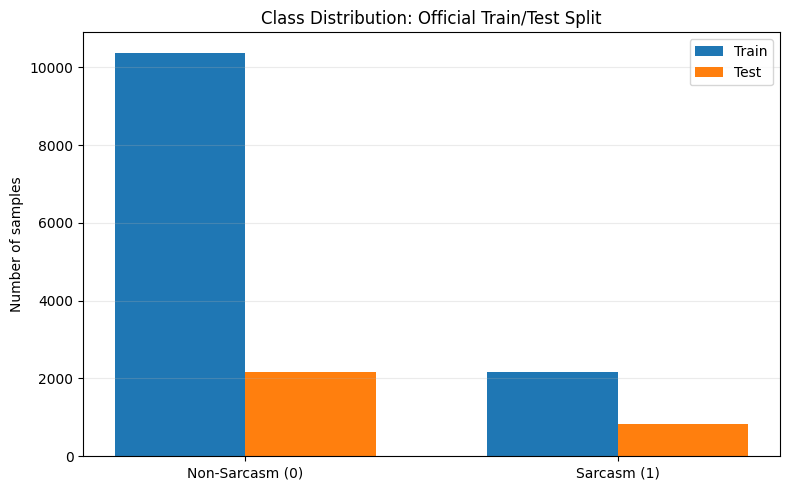

In [8]:
def build_dataset_summary(df: pd.DataFrame, split: str) -> pd.DataFrame:
    counts = df[LABEL_COLUMN].value_counts().reindex([0, 1], fill_value=0)
    rows = []
    for label, label_name in [(0, "Non-Sarcasm"), (1, "Sarcasm")]:
        rows.append({
            "split": split,
            "label": label,
            "label_name": label_name,
            "count": int(counts[label]),
            "percentage": float(counts[label] / len(df) * 100),
            "total_rows": int(len(df)),
        })
    return pd.DataFrame(rows)

dataset_summary = pd.concat([
    build_dataset_summary(train_df, "Train"),
    build_dataset_summary(test_df, "Test")
], ignore_index=True)
dataset_summary.to_csv(TABLES_DIR / "dataset_summary.csv", index=False)
display(dataset_summary)

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(2)
width = 0.35
train_counts = dataset_summary.query("split == 'Train'")["count"].to_numpy()
test_counts = dataset_summary.query("split == 'Test'")["count"].to_numpy()
ax.bar(x - width/2, train_counts, width, label="Train")
ax.bar(x + width/2, test_counts, width, label="Test")
ax.set_xticks(x, ["Non-Sarcasm (0)", "Sarcasm (1)"])
ax.set_ylabel("Number of samples")
ax.set_title("Class Distribution: Official Train/Test Split")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. MARBERTv2 Loading

In [9]:
print(f"Loading local MARBERTv2 from: {MODEL_PATH}")
tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH, local_files_only=True)
model = AutoModel.from_pretrained(MODEL_PATH, local_files_only=True)
model.eval()
model.to(DEVICE)

hidden_size = int(model.config.hidden_size)
if hidden_size != 768:
    raise ValueError(f"Expected MARBERTv2 hidden size 768, found {hidden_size}")

for param in model.parameters():
    param.requires_grad_(False)

print("Device:", DEVICE)
print("Hidden size:", hidden_size)
print("Model training mode:", model.training)

Loading local MARBERTv2 from: <PROJECT_ROOT>\models\MARBERTv2


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 430.97it/s, Materializing param=pooler.dense.weight]                               


Device: cuda
Hidden size: 768
Model training mode: False


## 9. Representation Functions

In [10]:
def k_to_tag(value: float) -> str:
    return str(value).replace(".", "p").replace("-", "m")

def representation_name(method: str, k_lower: Optional[float] = None, k_upper: Optional[float] = None) -> str:
    if method != "MFMP":
        return method
    return f"MFMP_kl{k_to_tag(float(k_lower))}_ku{k_to_tag(float(k_upper))}"

def representation_cache_path(split: str, method: str, k_lower: Optional[float] = None, k_upper: Optional[float] = None) -> Path:
    return CACHE_DIR / f"{split.lower()}_{representation_name(method, k_lower, k_upper)}.npy"

def calculate_sentence_statistics(hidden_states: torch.Tensor, attention_mask: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    """Return valid-token mean vectors, token magnitudes, abs sentence-local z-scores, and valid-token counts."""
    valid = attention_mask.bool()
    valid_f = valid.to(hidden_states.dtype)
    counts = valid_f.sum(dim=1).clamp_min(1.0)

    mean_vectors = (hidden_states * valid_f.unsqueeze(-1)).sum(dim=1) / counts.unsqueeze(-1)
    magnitudes = torch.linalg.vector_norm(hidden_states, ord=2, dim=-1)
    mu = (magnitudes * valid_f).sum(dim=1) / counts
    centered = (magnitudes - mu.unsqueeze(1)) * valid_f
    variance = centered.pow(2).sum(dim=1) / counts  # population variance, ddof=0
    sigma = torch.sqrt(variance).clamp_min(EPSILON)
    z = (magnitudes - mu.unsqueeze(1)) / sigma.unsqueeze(1)
    abs_z = torch.abs(z)
    return mean_vectors, magnitudes, abs_z, counts

def calculate_mfmp_from_hidden(
    hidden_states: torch.Tensor,
    attention_mask: torch.Tensor,
    mean_vectors: torch.Tensor,
    abs_z: torch.Tensor,
    k_lower: float,
    k_upper: float,
) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    """MFMP on whole token vectors. PAD excluded; CLS/SEP are treated like all other valid tokens."""
    valid = attention_mask.bool()
    retained = valid & (abs_z >= k_lower) & (abs_z <= k_upper)
    retained_counts = retained.sum(dim=1)
    summed = (hidden_states * retained.unsqueeze(-1).to(hidden_states.dtype)).sum(dim=1)
    safe_counts = retained_counts.clamp_min(1).to(hidden_states.dtype).unsqueeze(-1)
    pooled = summed / safe_counts
    fallback_mask = retained_counts == 0
    pooled = torch.where(fallback_mask.unsqueeze(-1), mean_vectors, pooled)
    return pooled, retained_counts, fallback_mask

## 10. CLS and Mean Pooling

In [11]:
# Sanity demonstration on a tiny synthetic tensor. This does not run MARBERTv2.
_synth_hidden = torch.randn(2, 5, 768)
_synth_mask = torch.tensor([[1, 1, 1, 0, 0], [1, 1, 1, 1, 0]])
_synth_mean, _synth_mag, _synth_abs_z, _synth_counts = calculate_sentence_statistics(_synth_hidden, _synth_mask)
assert _synth_hidden[:, 0, :].shape == (2, 768)
assert _synth_mean.shape == (2, 768)
print("CLS and Mean pooling dimensionality sanity check passed: 768")
del _synth_hidden, _synth_mask, _synth_mean, _synth_mag, _synth_abs_z, _synth_counts

CLS and Mean pooling dimensionality sanity check passed: 768


## 11. MFMP Magnitude Computation

In [12]:
# MFMP sanity check: filtering decisions are scalar per token, while pooling uses the ORIGINAL contextual vectors.
_synth_hidden = torch.randn(3, 7, 768)
_synth_mask = torch.tensor([
    [1, 1, 1, 1, 0, 0, 0],
    [1, 1, 1, 1, 1, 0, 0],
    [1, 1, 1, 1, 1, 1, 1],
])
_synth_mean, _, _synth_abs_z, _ = calculate_sentence_statistics(_synth_hidden, _synth_mask)
_synth_mfmp, _counts, _fallback = calculate_mfmp_from_hidden(
    _synth_hidden, _synth_mask, _synth_mean, _synth_abs_z, 0.0001, 3.0
)
assert _synth_mfmp.shape == (3, 768)
print("MFMP dimensionality sanity check passed: 768")
del _synth_hidden, _synth_mask, _synth_mean, _synth_abs_z, _synth_mfmp, _counts, _fallback

MFMP dimensionality sanity check passed: 768


## 12. Absolute Z-Score Distribution Analysis

In [13]:
ZONE_EDGES = [0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, np.inf]
ZONE_LABELS = ["0-0.5", "0.5-1", "1-1.5", "1.5-2", "2-2.5", "2.5-3", "3-3.5", "3.5-4", "4-4.5", "4.5-5", ">=5"]

# Plots are generated after representation extraction from the same sentence-local |z| values used by MFMP.
print("Absolute-Z analysis will be populated during the one-pass TRAIN extraction.")

Absolute-Z analysis will be populated during the one-pass TRAIN extraction.


## 13. MFMP K Search Space

In [14]:
k_grid_df = pd.DataFrame(K_CONFIGS, columns=["K_lower", "K_upper"])
print(f"Total valid MFMP K configurations: {len(k_grid_df)}")
display(k_grid_df)

Total valid MFMP K configurations: 30


,K_lower,K_upper
0,0.0001,0.5
1,0.0001,1.0
2,0.0001,1.5
3,0.0001,2.0
4,0.0001,2.5
5,0.0001,3.0
6,0.0001,3.5
7,0.0001,4.0
8,0.0001,4.5
9,0.0001,5.0


## 14. Representation Extraction and Caching

In [15]:
def model_fingerprint(model_path: Path) -> str:
    entries = []
    for p in sorted(model_path.rglob("*")):
        if p.is_file():
            stat = p.stat()
            entries.append((str(p.relative_to(model_path)), int(stat.st_size), int(stat.st_mtime_ns)))
    payload = json.dumps(entries, sort_keys=True).encode("utf-8")
    return hashlib.sha256(payload).hexdigest()

MODEL_FINGERPRINT = model_fingerprint(MODEL_PATH)
CACHE_SIGNATURE_PAYLOAD = {
    "train_fingerprint": TRAIN_FINGERPRINT,
    "test_fingerprint": TEST_FINGERPRINT,
    "model_fingerprint": MODEL_FINGERPRINT,
    "max_len": MAX_LEN,
    "k_lower_values": K_LOWER_VALUES,
    "k_upper_values": K_UPPER_VALUES,
    "hidden_size": hidden_size,
}
CACHE_SIGNATURE = hashlib.sha256(json.dumps(CACHE_SIGNATURE_PAYLOAD, sort_keys=True).encode("utf-8")).hexdigest()
CACHE_MANIFEST_PATH = CACHE_DIR / "cache_manifest.json"
TRAIN_MANIFEST_PATH = CACHE_DIR / "train_extraction_manifest.json"
TEST_MANIFEST_PATH = CACHE_DIR / "test_extraction_manifest.json"


def expected_representation_paths(split: str) -> List[Path]:
    paths = [representation_cache_path(split, "CLS"), representation_cache_path(split, "Mean")]
    paths += [representation_cache_path(split, "MFMP", kl, ku) for kl, ku in K_CONFIGS]
    return paths


def split_cache_is_valid(split: str) -> bool:
    split_lower = split.lower()
    manifest_path = TRAIN_MANIFEST_PATH if split_lower == "train" else TEST_MANIFEST_PATH
    if not manifest_path.exists():
        return False
    try:
        manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    except Exception:
        return False
    if manifest.get("cache_signature") != CACHE_SIGNATURE:
        return False
    required = expected_representation_paths(split_lower)
    required += [TABLES_DIR / f"{split_lower}_k_token_statistics.csv", TABLES_DIR / f"{split_lower}_absolute_z_zones.csv"]
    if split_lower == "train":
        required.append(CACHE_DIR / "train_abs_z_valid_tokens.npy")
    return all(path.exists() for path in required)

def cache_is_valid() -> bool:
    return split_cache_is_valid("train") and split_cache_is_valid("test")


def open_representation_memmaps(split: str, n_rows: int) -> Dict[Tuple[str, Optional[float], Optional[float]], np.memmap]:
    maps: Dict[Tuple[str, Optional[float], Optional[float]], np.memmap] = {}
    for method in ["CLS", "Mean"]:
        path = representation_cache_path(split, method)
        maps[(method, None, None)] = np.lib.format.open_memmap(path, mode="w+", dtype=REPRESENTATION_DTYPE, shape=(n_rows, hidden_size))
    for kl, ku in K_CONFIGS:
        path = representation_cache_path(split, "MFMP", kl, ku)
        maps[("MFMP", kl, ku)] = np.lib.format.open_memmap(path, mode="w+", dtype=REPRESENTATION_DTYPE, shape=(n_rows, hidden_size))
    return maps


def extract_split_representations(df: pd.DataFrame, split: str, collect_raw_abs_z: bool) -> Tuple[pd.DataFrame, pd.DataFrame, Optional[np.ndarray]]:
    n = len(df)
    memmaps = open_representation_memmaps(split, n)
    texts = df[TEXT_COLUMN].tolist()

    k_stats = {
        (kl, ku): {"total_valid_tokens": 0, "retained_tokens": 0, "fallback_sentences": 0}
        for kl, ku in K_CONFIGS
    }
    zone_counts = np.zeros(len(ZONE_LABELS), dtype=np.int64)
    raw_abs_z_chunks: List[np.ndarray] = []

    batch_starts = list(range(0, n, BATCH_SIZE))
    print(f"{split}: {n} samples, {len(batch_starts)} batches, one MARBERTv2 pass.")

    with torch.no_grad():
        for start in tqdm(batch_starts, desc=f"Extracting {split} representations"):
            end = min(start + BATCH_SIZE, n)
            batch_texts = texts[start:end]
            encoded = tokenizer(
                batch_texts,
                padding=True,
                truncation=True,
                max_length=MAX_LEN,
                return_tensors="pt",
            )
            encoded = {k: v.to(DEVICE) for k, v in encoded.items()}
            outputs = model(**encoded)
            hidden = outputs.last_hidden_state
            attention_mask = encoded["attention_mask"]

            mean_vec, _magnitudes, abs_z, valid_counts = calculate_sentence_statistics(hidden, attention_mask)
            cls_vec = hidden[:, 0, :]

            memmaps[("CLS", None, None)][start:end] = cls_vec.detach().float().cpu().numpy()
            memmaps[("Mean", None, None)][start:end] = mean_vec.detach().float().cpu().numpy()

            valid_mask = attention_mask.bool()
            valid_abs_z = abs_z[valid_mask].detach().float().cpu().numpy()
            if collect_raw_abs_z:
                raw_abs_z_chunks.append(valid_abs_z.astype(np.float32, copy=False))
            batch_zone_counts, _ = np.histogram(valid_abs_z, bins=ZONE_EDGES)
            zone_counts += batch_zone_counts.astype(np.int64)
            batch_total_valid = int(valid_mask.sum().item())

            for kl, ku in K_CONFIGS:
                pooled, retained_counts, fallback_mask = calculate_mfmp_from_hidden(
                    hidden, attention_mask, mean_vec, abs_z, kl, ku
                )
                memmaps[("MFMP", kl, ku)][start:end] = pooled.detach().float().cpu().numpy()
                k_stats[(kl, ku)]["total_valid_tokens"] += batch_total_valid
                k_stats[(kl, ku)]["retained_tokens"] += int(retained_counts.sum().item())
                k_stats[(kl, ku)]["fallback_sentences"] += int(fallback_mask.sum().item())

            del outputs, hidden, attention_mask, mean_vec, _magnitudes, abs_z, valid_mask, valid_abs_z, encoded
            if torch.cuda.is_available() and (start // BATCH_SIZE) % 25 == 0:
                torch.cuda.empty_cache()

    for mmap in memmaps.values():
        mmap.flush()
    del memmaps
    gc.collect()

    k_rows = []
    for (kl, ku), stat in k_stats.items():
        total = stat["total_valid_tokens"]
        retained = stat["retained_tokens"]
        excluded = total - retained
        k_rows.append({
            "split": split,
            "K_lower": kl,
            "K_upper": ku,
            "total_valid_tokens": total,
            "retained_tokens": retained,
            "excluded_tokens": excluded,
            "retained_percentage": retained / total * 100 if total else np.nan,
            "excluded_percentage": excluded / total * 100 if total else np.nan,
            "fallback_sentences": stat["fallback_sentences"],
        })
    k_stats_df = pd.DataFrame(k_rows)

    zone_total = int(zone_counts.sum())
    zone_df = pd.DataFrame({
        "split": split,
        "zone": ZONE_LABELS,
        "count": zone_counts,
        "percentage": zone_counts / max(zone_total, 1) * 100,
    })

    raw_abs_z = np.concatenate(raw_abs_z_chunks) if collect_raw_abs_z else None
    return k_stats_df, zone_df, raw_abs_z


# TRAIN cache is independent from TEST cache, so an interrupted run does not redo completed encoder work.
if split_cache_is_valid("train"):
    print("Valid TRAIN representation cache found. TRAIN MARBERTv2 pass will be skipped.")
    train_k_stats = pd.read_csv(TABLES_DIR / "train_k_token_statistics.csv")
    train_zone_df = pd.read_csv(TABLES_DIR / "train_absolute_z_zones.csv")
    train_abs_z = np.load(CACHE_DIR / "train_abs_z_valid_tokens.npy", mmap_mode="r")
else:
    train_k_stats, train_zone_df, train_abs_z = extract_split_representations(train_df, "Train", collect_raw_abs_z=True)
    train_k_stats.to_csv(TABLES_DIR / "train_k_token_statistics.csv", index=False)
    train_zone_df.to_csv(TABLES_DIR / "train_absolute_z_zones.csv", index=False)
    np.save(CACHE_DIR / "train_abs_z_valid_tokens.npy", np.asarray(train_abs_z, dtype=np.float32))
    TRAIN_MANIFEST_PATH.write_text(json.dumps({
        "cache_signature": CACHE_SIGNATURE,
        "created_utc": datetime.now(timezone.utc).isoformat(),
        "split": "train", "rows": len(train_df), "hidden_size": hidden_size,
    }, indent=2), encoding="utf-8")

if split_cache_is_valid("test"):
    print("Valid TEST representation cache found. TEST MARBERTv2 pass will be skipped.")
    test_k_stats = pd.read_csv(TABLES_DIR / "test_k_token_statistics.csv")
    test_zone_df = pd.read_csv(TABLES_DIR / "test_absolute_z_zones.csv")
else:
    test_k_stats, test_zone_df, _ = extract_split_representations(test_df, "Test", collect_raw_abs_z=False)
    test_k_stats.to_csv(TABLES_DIR / "test_k_token_statistics.csv", index=False)
    test_zone_df.to_csv(TABLES_DIR / "test_absolute_z_zones.csv", index=False)
    TEST_MANIFEST_PATH.write_text(json.dumps({
        "cache_signature": CACHE_SIGNATURE,
        "created_utc": datetime.now(timezone.utc).isoformat(),
        "split": "test", "rows": len(test_df), "hidden_size": hidden_size,
    }, indent=2), encoding="utf-8")

k_token_statistics = pd.concat([train_k_stats, test_k_stats], ignore_index=True)
k_token_statistics.to_csv(TABLES_DIR / "k_token_statistics.csv", index=False)
absolute_z_zone_distribution = pd.concat([train_zone_df, test_zone_df], ignore_index=True)
absolute_z_zone_distribution.to_csv(TABLES_DIR / "absolute_z_zone_distribution.csv", index=False)

# One numerical table covering TRAIN zones, K_upper cumulative coverage, and K_lower lower-tail exclusion.
train_abs_z = np.load(CACHE_DIR / "train_abs_z_valid_tokens.npy", mmap_mode="r")
dist_rows = []
total_train_tokens = len(train_abs_z)
for row in train_zone_df.itertuples(index=False):
    dist_rows.append({"analysis_type": "zone", "parameter": row.zone, "count": int(row.count), "percentage": float(row.percentage)})
for ku in K_UPPER_VALUES:
    count = int(np.sum(train_abs_z <= ku))
    dist_rows.append({"analysis_type": "K_upper_leq", "parameter": ku, "count": count, "percentage": count / total_train_tokens * 100})
for kl in K_LOWER_VALUES:
    count = int(np.sum(train_abs_z < kl))
    dist_rows.append({"analysis_type": "K_lower_lt", "parameter": kl, "count": count, "percentage": count / total_train_tokens * 100})
magnitude_distribution = pd.DataFrame(dist_rows)
magnitude_distribution.to_csv(TABLES_DIR / "magnitude_distribution.csv", index=False)

manifest = {
    "cache_signature": CACHE_SIGNATURE,
    "signature_payload": CACHE_SIGNATURE_PAYLOAD,
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "train_rows": len(train_df),
    "test_rows": len(test_df),
    "hidden_size": hidden_size,
    "representations_per_split": 42,
    "train_cache_valid": split_cache_is_valid("train"),
    "test_cache_valid": split_cache_is_valid("test"),
}
CACHE_MANIFEST_PATH.write_text(json.dumps(manifest, indent=2), encoding="utf-8")

# Shape assertions for every cached representation.
def validate_representation_cache() -> None:
    for split, n_rows in [("train", len(train_df)), ("test", len(test_df))]:
        for method in ["CLS", "Mean"]:
            arr = np.load(representation_cache_path(split, method), mmap_mode="r")
            assert arr.shape == (n_rows, 768), f"Bad shape: {split} {method} {arr.shape}"
        for kl, ku in K_CONFIGS:
            arr = np.load(representation_cache_path(split, "MFMP", kl, ku), mmap_mode="r")
            assert arr.shape == (n_rows, 768), f"Bad shape: {split} MFMP ({kl},{ku}) {arr.shape}"

validate_representation_cache()
print(f"CLS Train: {np.load(representation_cache_path('train','CLS'), mmap_mode='r').shape}")
print(f"Mean Train: {np.load(representation_cache_path('train','Mean'), mmap_mode='r').shape}")
for kl, ku in K_CONFIGS:
    print(f"MFMP Train K=({kl}, {ku}): {np.load(representation_cache_path('train','MFMP',kl,ku), mmap_mode='r').shape}")

Train: 12548 samples, 393 batches, one MARBERTv2 pass.


Extracting Train representations: 100%|██████████| 393/393 [00:31<00:00, 12.62it/s]


Test: 3000 samples, 94 batches, one MARBERTv2 pass.


Extracting Test representations: 100%|██████████| 94/94 [00:09<00:00, 10.00it/s]


CLS Train: (12548, 768)
Mean Train: (12548, 768)
MFMP Train K=(0.0001, 0.5): (12548, 768)
MFMP Train K=(0.0001, 1.0): (12548, 768)
MFMP Train K=(0.0001, 1.5): (12548, 768)
MFMP Train K=(0.0001, 2.0): (12548, 768)
MFMP Train K=(0.0001, 2.5): (12548, 768)
MFMP Train K=(0.0001, 3.0): (12548, 768)
MFMP Train K=(0.0001, 3.5): (12548, 768)
MFMP Train K=(0.0001, 4.0): (12548, 768)
MFMP Train K=(0.0001, 4.5): (12548, 768)
MFMP Train K=(0.0001, 5.0): (12548, 768)
MFMP Train K=(0.001, 0.5): (12548, 768)
MFMP Train K=(0.001, 1.0): (12548, 768)
MFMP Train K=(0.001, 1.5): (12548, 768)
MFMP Train K=(0.001, 2.0): (12548, 768)
MFMP Train K=(0.001, 2.5): (12548, 768)
MFMP Train K=(0.001, 3.0): (12548, 768)
MFMP Train K=(0.001, 3.5): (12548, 768)
MFMP Train K=(0.001, 4.0): (12548, 768)
MFMP Train K=(0.001, 4.5): (12548, 768)
MFMP Train K=(0.001, 5.0): (12548, 768)
MFMP Train K=(0.01, 0.5): (12548, 768)
MFMP Train K=(0.01, 1.0): (12548, 768)
MFMP Train K=(0.01, 1.5): (12548, 768)
MFMP Train K=(0.01, 2.0)

### Magnitude / Absolute Z-Score Plots

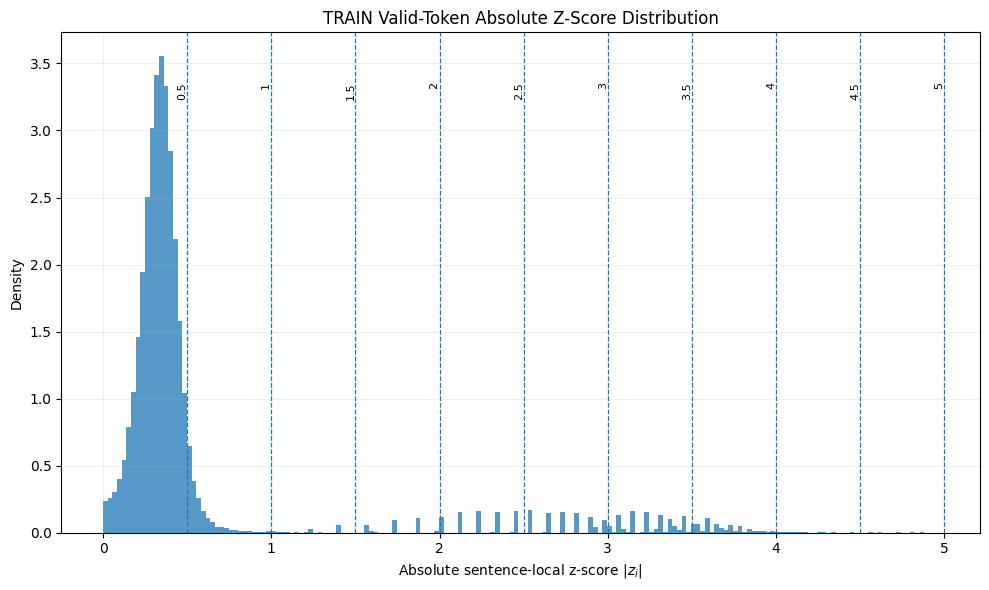

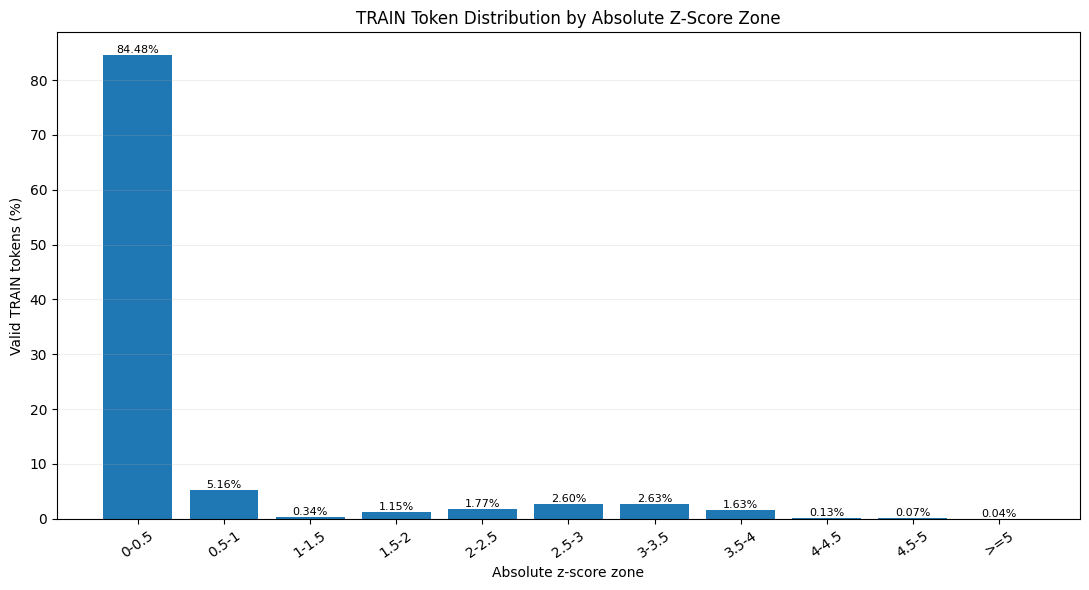

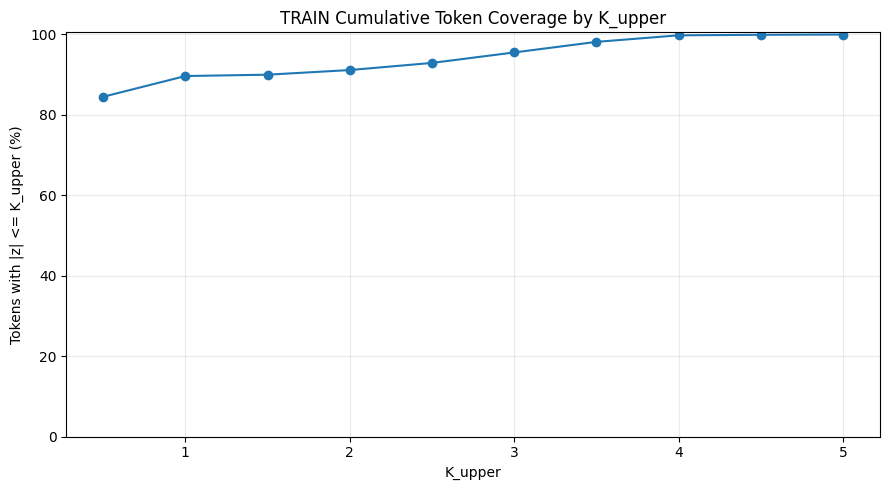

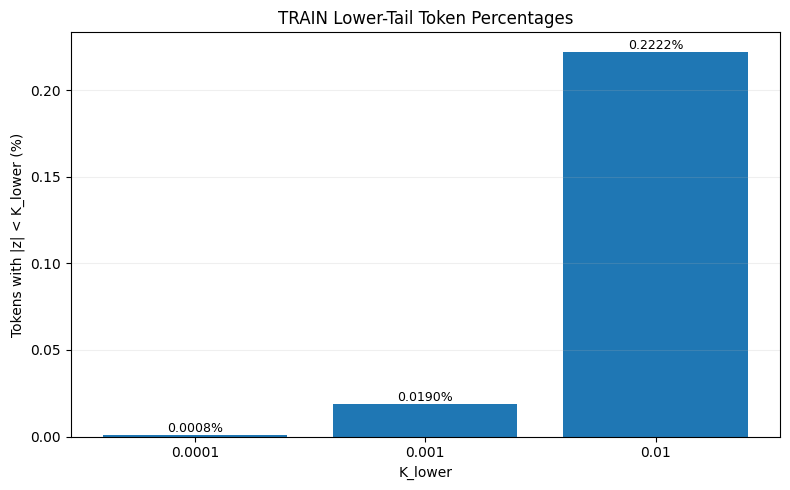

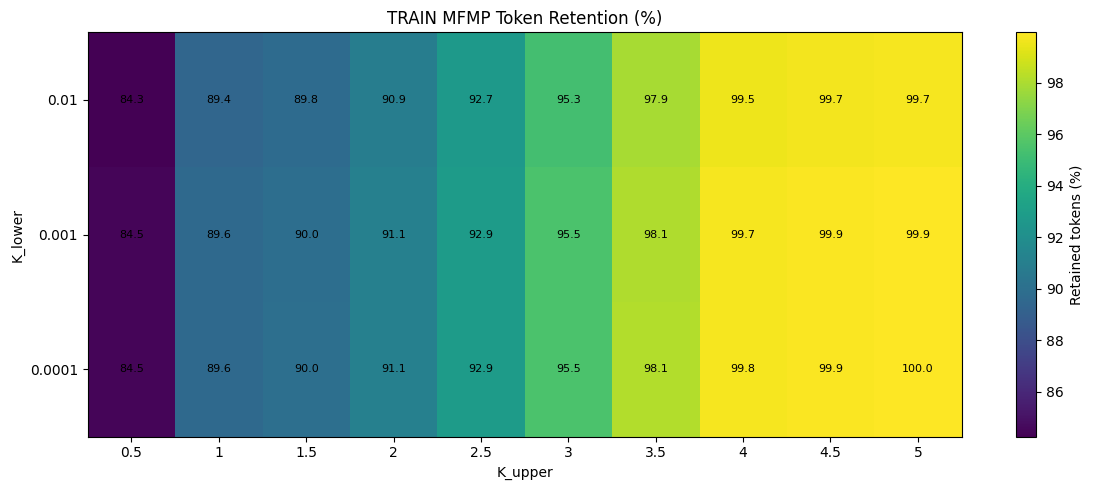

,analysis_type,parameter,count,percentage
0,zone,0-0.5,204548,84.483122
1,zone,0.5-1,12482,5.155359
2,zone,1-1.5,813,0.335788
3,zone,1.5-2,2790,1.152335
4,zone,2-2.5,4285,1.769806
5,zone,2.5-3,6307,2.604939
6,zone,3-3.5,6360,2.626829
7,zone,3.5-4,3942,1.628138
8,zone,4-4.5,320,0.132168
9,zone,4.5-5,170,0.070214


,split,K_lower,K_upper,total_valid_tokens,retained_tokens,excluded_tokens,retained_percentage,excluded_percentage,fallback_sentences
0,Train,0.0001,0.5,242117,204546,37571,84.482296,15.517704,920
1,Train,0.0001,1.0,242117,217028,25089,89.637655,10.362345,0
2,Train,0.0001,1.5,242117,217841,24276,89.973443,10.026557,0
3,Train,0.0001,2.0,242117,220631,21486,91.125778,8.874222,0
4,Train,0.0001,2.5,242117,224916,17201,92.895584,7.104416,0
5,Train,0.0001,3.0,242117,231223,10894,95.500522,4.499478,0
6,Train,0.0001,3.5,242117,237583,4534,98.127352,1.872648,0
7,Train,0.0001,4.0,242117,241525,592,99.755490,0.244510,0
8,Train,0.0001,4.5,242117,241845,272,99.887658,0.112342,0
9,Train,0.0001,5.0,242117,242015,102,99.957872,0.042128,0


In [16]:
train_abs_z = np.load(CACHE_DIR / "train_abs_z_valid_tokens.npy", mmap_mode="r")

# Plot 1: histogram/density of |z| with K_upper reference lines.
fig, ax = plt.subplots(figsize=(10, 6))
finite_max = min(float(np.quantile(train_abs_z, 0.9995)), 8.0)
bins = np.linspace(0, max(finite_max, 0.5), 180)
ax.hist(train_abs_z, bins=bins, density=True, alpha=0.75)
for ku in K_UPPER_VALUES:
    ax.axvline(ku, linestyle="--", linewidth=0.9)
    ax.text(ku, ax.get_ylim()[1] * 0.90, f"{ku:g}", rotation=90, va="top", ha="right", fontsize=8)
ax.set_xlabel(r"Absolute sentence-local z-score $|z_i|$")
ax.set_ylabel("Density")
ax.set_title("TRAIN Valid-Token Absolute Z-Score Distribution")
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "absolute_z_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot 2: zones.
zone_plot_df = magnitude_distribution.query("analysis_type == 'zone'").copy()
fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.bar(zone_plot_df["parameter"].astype(str), zone_plot_df["percentage"])
ax.set_ylabel("Valid TRAIN tokens (%)")
ax.set_xlabel("Absolute z-score zone")
ax.set_title("TRAIN Token Distribution by Absolute Z-Score Zone")
ax.tick_params(axis="x", rotation=35)
for bar, pct in zip(bars, zone_plot_df["percentage"]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f"{pct:.2f}%", ha="center", va="bottom", fontsize=8)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "magnitude_zones.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot 3: cumulative <= K_upper.
ku_df = magnitude_distribution.query("analysis_type == 'K_upper_leq'").copy()
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ku_df["parameter"].astype(float), ku_df["percentage"], marker="o")
ax.set_xlabel("K_upper")
ax.set_ylabel("Tokens with |z| <= K_upper (%)")
ax.set_title("TRAIN Cumulative Token Coverage by K_upper")
ax.set_ylim(0, 100.5)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "k_upper_cumulative_percentage.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot 4: lower-tail percentages.
kl_df = magnitude_distribution.query("analysis_type == 'K_lower_lt'").copy()
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(kl_df["parameter"].astype(str), kl_df["percentage"])
ax.set_xlabel("K_lower")
ax.set_ylabel("Tokens with |z| < K_lower (%)")
ax.set_title("TRAIN Lower-Tail Token Percentages")
for bar, pct in zip(bars, kl_df["percentage"]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f"{pct:.4f}%", ha="center", va="bottom", fontsize=9)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "k_lower_excluded_percentage.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot 5: 40-configuration retention heatmap using TRAIN statistics only.
heat = k_token_statistics.query("split == 'Train'").pivot(index="K_lower", columns="K_upper", values="retained_percentage")
fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(heat.values, aspect="auto", origin="lower")
ax.set_xticks(np.arange(len(heat.columns)), [f"{x:g}" for x in heat.columns])
ax.set_yticks(np.arange(len(heat.index)), [f"{x:g}" for x in heat.index])
ax.set_xlabel("K_upper")
ax.set_ylabel("K_lower")
ax.set_title("TRAIN MFMP Token Retention (%)")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.iloc[i, j]:.1f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="Retained tokens (%)")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "k_retention_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

display(magnitude_distribution)
display(k_token_statistics.head(10))

## 15. Cross-Validation Folds

In [17]:
y_train = train_df[LABEL_COLUMN].to_numpy(dtype=np.int64)

# One fixed 10-fold stratified split is reused for every representation,
# hyperparameter candidate, and classifier for paired/fair comparison.
skf = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_SEED,
)
FOLDS = list(skf.split(np.zeros(len(y_train)), y_train))

fold_id = np.full(len(y_train), -1, dtype=np.int64)
for fold_idx, (train_idx, val_idx) in enumerate(FOLDS):
    if np.any(fold_id[val_idx] != -1):
        raise RuntimeError(
            "A TRAIN sample was assigned to more than one validation fold."
        )
    fold_id[val_idx] = fold_idx

assert np.all(fold_id >= 0), (
    "Every TRAIN sample must receive exactly one validation fold ID."
)

fold_assignments = pd.DataFrame({
    "row_id": train_df["row_id"],
    "fold_id": fold_id,
    "label": y_train,
})
fold_assignments.to_csv(
    CONFIG_DIR / "cv_fold_assignments.csv",
    index=False,
)

print("10-fold validation class distributions:")
for fold_idx, (_, val_idx) in enumerate(FOLDS):
    counts = (
        pd.Series(y_train[val_idx])
        .value_counts()
        .reindex([0, 1], fill_value=0)
    )
    percentages = counts / len(val_idx) * 100
    print(
        f"Fold {fold_idx:02d}: n={len(val_idx)}, "
        f"counts={counts.to_dict()}, "
        f"percentages={percentages.round(2).to_dict()}"
    )

FOLD_SIGNATURE = hashlib.sha256(fold_id.tobytes()).hexdigest()
print("Fold signature:", FOLD_SIGNATURE)
print(
    f"Model selection protocol: {CV_FOLDS}-fold stratified cross-validation "
    "with fixed default classifier thresholds."
)


10-fold validation class distributions:
Fold 00: n=1255, counts={0: 1038, 1: 217}, percentages={0: 82.71, 1: 17.29}
Fold 01: n=1255, counts={0: 1038, 1: 217}, percentages={0: 82.71, 1: 17.29}
Fold 02: n=1255, counts={0: 1038, 1: 217}, percentages={0: 82.71, 1: 17.29}
Fold 03: n=1255, counts={0: 1038, 1: 217}, percentages={0: 82.71, 1: 17.29}
Fold 04: n=1255, counts={0: 1038, 1: 217}, percentages={0: 82.71, 1: 17.29}
Fold 05: n=1255, counts={0: 1038, 1: 217}, percentages={0: 82.71, 1: 17.29}
Fold 06: n=1255, counts={0: 1038, 1: 217}, percentages={0: 82.71, 1: 17.29}
Fold 07: n=1255, counts={0: 1038, 1: 217}, percentages={0: 82.71, 1: 17.29}
Fold 08: n=1254, counts={0: 1038, 1: 216}, percentages={0: 82.78, 1: 17.22}
Fold 09: n=1254, counts={0: 1038, 1: 216}, percentages={0: 82.78, 1: 17.22}
Fold signature: 391a40e39d38fb7057fcf337c190884af979668706594499d91b6378add510d3
Model selection protocol: 10-fold stratified cross-validation with fixed default classifier thresholds.


## 16. Metrics Functions

In [18]:
def safe_binary_metrics_from_confusion(tn: np.ndarray, fp: np.ndarray, fn: np.ndarray, tp: np.ndarray):
    def div(num, den):
        return np.divide(num, den, out=np.zeros_like(num, dtype=np.float64), where=den != 0)
    p1 = div(tp, tp + fp)
    r1 = div(tp, tp + fn)
    f1_1 = div(2 * p1 * r1, p1 + r1)
    p0 = div(tn, tn + fn)
    r0 = div(tn, tn + fp)
    f1_0 = div(2 * p0 * r0, p0 + r0)
    acc = div(tp + tn, tp + tn + fp + fn)
    macro_f1 = (f1_0 + f1_1) / 2
    return acc, p1, r1, f1_1, p0, r0, f1_0, macro_f1


def optimize_threshold(y_true: np.ndarray, scores: np.ndarray) -> Tuple[float, pd.DataFrame]:
    """
    Optimize the decision threshold ONLY after a representation/hyperparameter
    configuration has already been selected using threshold-independent OOF metrics.

    Primary objective:
      1) Macro-F1
    Tie-breakers:
      2) F1-Sarcasm
      3) Recall-Sarcasm
      4) Accuracy
    """
    y_true = np.asarray(y_true, dtype=np.int64)
    scores = np.asarray(scores, dtype=np.float64)
    if len(y_true) != len(scores) or np.isnan(scores).any():
        raise ValueError("Threshold optimization requires complete, finite pooled OOF scores aligned with y_true.")

    unique_scores = np.unique(scores)
    midpoints = (
        (unique_scores[:-1] + unique_scores[1:]) / 2.0
        if len(unique_scores) > 1
        else np.array([], dtype=np.float64)
    )
    candidates = np.unique(np.concatenate([unique_scores, midpoints]))

    order = np.argsort(scores, kind="mergesort")
    sorted_scores = scores[order]
    sorted_y = y_true[order]
    prefix_pos = np.concatenate([[0], np.cumsum(sorted_y)])
    total_pos = int(prefix_pos[-1])
    n = len(y_true)

    idx = np.searchsorted(sorted_scores, candidates, side="left")
    tp = total_pos - prefix_pos[idx]
    predicted_pos = n - idx
    fp = predicted_pos - tp
    fn = total_pos - tp
    tn = idx - fn

    acc, p1, r1, f1_1, p0, r0, f1_0, macro_f1 = safe_binary_metrics_from_confusion(
        tn, fp, fn, tp
    )

    candidate_df = pd.DataFrame({
        "threshold": candidates,
        "macro_f1": macro_f1,
        "f1_sarcasm": f1_1,
        "recall_sarcasm": r1,
        "accuracy": acc,
    })

    candidate_df = candidate_df.sort_values(
        ["macro_f1", "f1_sarcasm", "recall_sarcasm", "accuracy", "threshold"],
        ascending=[False, False, False, False, True],
        kind="mergesort",
    ).reset_index(drop=True)

    best_threshold = float(candidate_df.iloc[0]["threshold"])
    return best_threshold, candidate_df


def calculate_ranking_metrics(y_true: np.ndarray, scores: np.ndarray) -> Dict[str, float]:
    """
    Threshold-independent OOF metrics used EXCLUSIVELY for configuration selection.

    Selection order:
      1) Average Precision
      2) PR-AUC
      3) ROC-AUC
    """
    y_true = np.asarray(y_true, dtype=np.int64)
    scores = np.asarray(scores, dtype=np.float64)

    if len(y_true) != len(scores) or np.isnan(scores).any():
        raise ValueError("Ranking metrics require complete, finite scores aligned with y_true.")

    pr_precision, pr_recall, _ = precision_recall_curve(y_true, scores)
    if len(pr_recall) > 1 and pr_recall[0] > pr_recall[-1]:
        pr_auc_value = auc(pr_recall[::-1], pr_precision[::-1])
    else:
        pr_auc_value = auc(pr_recall, pr_precision)

    return {
        "average_precision": float(average_precision_score(y_true, scores)),
        "pr_auc": float(pr_auc_value),
        "roc_auc": float(roc_auc_score(y_true, scores)),
    }


def calculate_metrics(y_true: np.ndarray, scores: np.ndarray, threshold: float) -> Dict[str, float]:
    """Full metrics after the configuration and its OOF-selected threshold are frozen."""
    y_true = np.asarray(y_true, dtype=np.int64)
    scores = np.asarray(scores, dtype=np.float64)
    y_pred = (scores >= threshold).astype(np.int64)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=[0, 1], zero_division=0
    )
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    ranking = calculate_ranking_metrics(y_true, scores)

    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_precision": float(np.mean(precision)),
        "macro_recall": float(np.mean(recall)),
        "macro_f1": float(np.mean(f1)),
        "precision_non_sarcasm": float(precision[0]),
        "recall_non_sarcasm": float(recall[0]),
        "f1_non_sarcasm": float(f1[0]),
        "precision_sarcasm": float(precision[1]),
        "recall_sarcasm": float(recall[1]),
        "f1_sarcasm": float(f1[1]),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "mcc": float(matthews_corrcoef(y_true, y_pred)),
        "cohen_kappa": float(cohen_kappa_score(y_true, y_pred)),
        **ranking,
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }




def validation_configuration_selection_key(
    row: Dict[str, Any]
) -> Tuple[float, float, float, float]:
    """Selection: mean Macro-F1 -> F1-Sar -> Recall-Sar -> Accuracy."""
    return (
        float(row["mean_macro_f1"]),
        float(row["mean_f1_sarcasm"]),
        float(row["mean_recall_sarcasm"]),
        float(row["mean_accuracy"]),
    )


## 17. 10-Fold Configuration Selection and Final OOF Threshold Optimization

Hyperparameter and MFMP threshold-range selection were performed using 10-fold stratified cross-validation on the training set. In each iteration, nine folds were used for training and one fold for validation. Candidate configurations were evaluated using the classifier's default decision threshold, and the configuration achieving the highest mean validation Macro-F1 was selected. After fixing the optimal configuration, 10-fold out-of-fold continuous scores on the complete training set were used to determine the final classification threshold by maximizing Macro-F1. The independent test set was used only for final evaluation.

During candidate comparison, Logistic Regression and Random Forest use a fixed threshold of `0.5`, while Linear SVM uses `0.0` on the decision function.

Candidate ranking is:

**Mean validation Macro-F1 → Mean validation F1-Sarcasm → Mean validation Recall-Sarcasm → Mean validation Accuracy.**

Average Precision, PR-AUC, and ROC-AUC are retained as threshold-independent diagnostic metrics from continuous validation scores, but they do not participate in configuration selection. Final threshold optimization is performed only after the winning configuration has been fixed.


In [19]:
def load_representation(
    split: str,
    method: str,
    k_lower: Optional[float] = None,
    k_upper: Optional[float] = None,
) -> np.ndarray:
    arr = np.load(
        representation_cache_path(split, method, k_lower, k_upper),
        mmap_mode="r",
    )
    expected_rows = len(train_df) if split.lower() == "train" else len(test_df)
    if arr.shape != (expected_rows, 768):
        raise RuntimeError(
            f"Representation/label mismatch for {split} {method}: {arr.shape}"
        )
    return arr


def build_estimator(classifier: str, params: Dict[str, Any]):
    if classifier == "LR":
        model_lr = LogisticRegression(
            C=float(params["C"]),
            solver="liblinear",
            class_weight="balanced",
            max_iter=3000,
            random_state=RANDOM_SEED,
        )
        return Pipeline([
            ("scaler", StandardScaler()),
            ("classifier", model_lr),
        ])

    if classifier == "SVM":
        model_svm = LinearSVC(
            C=float(params["C"]),
            class_weight="balanced",
            max_iter=10000,
            random_state=RANDOM_SEED,
            dual=SVM_DUAL_SETTING,
        )
        return Pipeline([
            ("scaler", StandardScaler()),
            ("classifier", model_svm),
        ])

    if classifier == "RF":
        return RandomForestClassifier(
            random_state=RANDOM_SEED,
            n_jobs=-1,
            **params,
        )

    raise ValueError(f"Unknown classifier: {classifier}")


def continuous_scores(
    fitted_estimator,
    classifier: str,
    X: np.ndarray,
) -> np.ndarray:
    if classifier in {"LR", "RF"}:
        return np.asarray(
            fitted_estimator.predict_proba(X)[:, 1],
            dtype=np.float64,
        )
    if classifier == "SVM":
        return np.asarray(
            fitted_estimator.decision_function(X),
            dtype=np.float64,
        )
    raise ValueError(classifier)


def default_decision_threshold(classifier: str) -> float:
    if classifier in {"LR", "RF"}:
        return 0.5
    if classifier == "SVM":
        return 0.0
    raise ValueError(classifier)


def generate_oof_scores(
    X: np.ndarray,
    y: np.ndarray,
    classifier: str,
    params: Dict[str, Any],
) -> np.ndarray:
    """
    Pooled 10-fold OOF continuous scores over FULL TRAIN.
    Called only after a configuration has already been selected.
    """
    if len(X) != len(y):
        raise RuntimeError("Representation rows do not match TRAIN labels.")

    oof_scores = np.full(len(y), np.nan, dtype=np.float64)
    assignment_count = np.zeros(len(y), dtype=np.int8)

    for train_idx, val_idx in FOLDS:
        estimator = build_estimator(classifier, params)
        estimator.fit(X[train_idx], y[train_idx])

        fold_scores = continuous_scores(
            estimator,
            classifier,
            X[val_idx],
        )
        oof_scores[val_idx] = fold_scores
        assignment_count[val_idx] += 1

        del estimator, fold_scores

    if not np.all(assignment_count == 1):
        raise RuntimeError(
            "Every TRAIN sample must receive exactly one OOF score."
        )
    if np.isnan(oof_scores).any():
        raise RuntimeError("OOF scores contain NaN.")

    return oof_scores


def evaluate_candidate_cv(
    X: np.ndarray,
    y: np.ndarray,
    classifier: str,
    params: Dict[str, Any],
) -> Tuple[Dict[str, float], pd.DataFrame, np.ndarray]:
    """
    Evaluate one candidate on the fixed 10 folds without threshold tuning.

    LR/RF use 0.5; SVM uses decision score 0.0.
    Fold metrics are computed independently and then averaged.
    """
    if len(X) != len(y):
        raise RuntimeError("Representation rows do not match TRAIN labels.")

    threshold = default_decision_threshold(classifier)

    pooled_validation_scores = np.full(
        len(y),
        np.nan,
        dtype=np.float64,
    )
    assignment_count = np.zeros(len(y), dtype=np.int8)
    fold_rows: List[Dict[str, Any]] = []

    for fold_idx, (train_idx, val_idx) in enumerate(FOLDS):
        estimator = build_estimator(classifier, params)
        estimator.fit(X[train_idx], y[train_idx])

        val_scores = continuous_scores(
            estimator,
            classifier,
            X[val_idx],
        )
        val_metrics = calculate_metrics(
            y[val_idx],
            val_scores,
            threshold,
        )

        pooled_validation_scores[val_idx] = val_scores
        assignment_count[val_idx] += 1

        fold_rows.append({
            "fold": fold_idx,
            "macro_f1": val_metrics["macro_f1"],
            "f1_sarcasm": val_metrics["f1_sarcasm"],
            "recall_sarcasm": val_metrics["recall_sarcasm"],
            "accuracy": val_metrics["accuracy"],
        })

        del estimator, val_scores

    if not np.all(assignment_count == 1):
        raise RuntimeError(
            "Each TRAIN sample must appear in exactly one validation fold."
        )
    if np.isnan(pooled_validation_scores).any():
        raise RuntimeError(
            "Candidate validation scores contain NaN."
        )

    fold_df = pd.DataFrame(fold_rows)
    diagnostic_metrics = calculate_ranking_metrics(
        y,
        pooled_validation_scores,
    )

    summary = {
        "mean_macro_f1": float(fold_df["macro_f1"].mean()),
        "std_macro_f1": float(fold_df["macro_f1"].std(ddof=1)),
        "mean_f1_sarcasm": float(fold_df["f1_sarcasm"].mean()),
        "mean_recall_sarcasm": float(fold_df["recall_sarcasm"].mean()),
        "mean_accuracy": float(fold_df["accuracy"].mean()),
        "average_precision": diagnostic_metrics["average_precision"],
        "pr_auc": diagnostic_metrics["pr_auc"],
        "roc_auc": diagnostic_metrics["roc_auc"],
        "candidate_threshold": float(threshold),
    }

    return summary, fold_df, pooled_validation_scores


def approach_specs() -> List[Tuple[str, Optional[float], Optional[float]]]:
    specs = [
        ("CLS", None, None),
        ("Mean", None, None),
    ]
    specs.extend(
        ("MFMP", kl, ku)
        for kl, ku in K_CONFIGS
    )
    return specs


def search_classifier(
    classifier: str,
    param_grid: List[Dict[str, Any]],
) -> Tuple[pd.DataFrame, pd.DataFrame, Dict[str, np.ndarray]]:
    """
    Candidate selection:
      1) mean validation Macro-F1
      2) mean validation F1-Sarcasm
      3) mean validation Recall-Sarcasm
      4) mean validation Accuracy

    AP / PR-AUC / ROC-AUC are diagnostic only.
    Threshold optimization is delayed until the three winners are fixed.
    """
    rows: List[Dict[str, Any]] = []
    best_by_approach: Dict[str, Dict[str, Any]] = {}

    specs = approach_specs()
    total_candidates = len(specs) * len(param_grid)
    selection_fits = total_candidates * CV_FOLDS
    final_threshold_fits = 3 * CV_FOLDS

    print(f"{classifier}: {total_candidates} candidate configurations.")
    print(
        f"{classifier}: configuration selection ≈ "
        f"{total_candidates} × {CV_FOLDS} = {selection_fits:,} model fits."
    )
    print(
        f"{classifier}: selected configurations require "
        f"3 × {CV_FOLDS} = {final_threshold_fits} additional "
        "OOF fits for final threshold selection."
    )

    progress = tqdm(
        total=total_candidates,
        desc=f"{classifier} 10-fold CV search",
    )

    search_id = 0

    # Stage A: fixed/default-threshold candidate evaluation.
    for method, kl, ku in specs:
        X = load_representation("train", method, kl, ku)

        for params in param_grid:
            cv_summary, fold_df, pooled_validation_scores = evaluate_candidate_cv(
                X=X,
                y=y_train,
                classifier=classifier,
                params=params,
            )

            row = {
                "search_id": search_id,
                "classifier": classifier,
                "method": method,
                "K_lower": kl,
                "K_upper": ku,
                "hyperparameters": json.dumps(params, sort_keys=True),
                "fold_signature": FOLD_SIGNATURE,
                "configuration_selected": False,
                "selected_threshold": np.nan,
                **cv_summary,
            }
            rows.append(row)

            current = best_by_approach.get(method)
            if (
                current is None
                or validation_configuration_selection_key(row)
                > validation_configuration_selection_key(current)
            ):
                best_by_approach[method] = row.copy()

            del cv_summary, fold_df, pooled_validation_scores
            search_id += 1
            progress.update(1)

        del X
        gc.collect()

    progress.close()

    results_df = pd.DataFrame(rows)

    # Audit-friendly aliases required in search CSVs.
    results_df["Classifier"] = results_df["classifier"]
    results_df["Approach"] = results_df["method"]
    results_df["Parameters"] = results_df["hyperparameters"]
    results_df["Mean_Macro_F1"] = results_df["mean_macro_f1"]
    results_df["Std_Macro_F1"] = results_df["std_macro_f1"]
    results_df["Mean_F1_Sar"] = results_df["mean_f1_sarcasm"]
    results_df["Mean_Recall_Sar"] = results_df["mean_recall_sarcasm"]
    results_df["Mean_Accuracy"] = results_df["mean_accuracy"]
    results_df["AP"] = results_df["average_precision"]
    results_df["PR_AUC"] = results_df["pr_auc"]
    results_df["ROC_AUC"] = results_df["roc_auc"]

    # Stage B: final threshold selection for selected configurations only.
    selected_rows: List[Dict[str, Any]] = []
    final_oof_score_map: Dict[str, np.ndarray] = {}

    for method in ["CLS", "Mean", "MFMP"]:
        selected = best_by_approach[method].copy()

        kl = None if pd.isna(selected["K_lower"]) else float(selected["K_lower"])
        ku = None if pd.isna(selected["K_upper"]) else float(selected["K_upper"])
        params = json.loads(selected["hyperparameters"])

        X_selected = load_representation(
            "train",
            method,
            kl,
            ku,
        )

        final_oof_scores = generate_oof_scores(
            X=X_selected,
            y=y_train,
            classifier=classifier,
            params=params,
        )

        # Only now is the operating threshold optimized.
        final_threshold, _ = optimize_threshold(
            y_train,
            final_oof_scores,
        )
        final_oof_metrics = calculate_metrics(
            y_train,
            final_oof_scores,
            final_threshold,
        )

        selected.update({
            "selected_threshold": float(final_threshold),
            "configuration_selected": True,
            **final_oof_metrics,
        })
        selected_rows.append(selected)
        final_oof_score_map[method] = final_oof_scores.copy()

        mask = results_df["search_id"].eq(int(selected["search_id"]))
        if int(mask.sum()) != 1:
            raise RuntimeError(
                f"{classifier} {method}: selected candidate row is not unique."
            )
        results_df.loc[mask, "configuration_selected"] = True
        results_df.loc[mask, "selected_threshold"] = float(final_threshold)

        del X_selected, final_oof_scores

    selected_df = pd.DataFrame(selected_rows)

    assert selected_df.shape[0] == 3
    assert set(selected_df["method"]) == {"CLS", "Mean", "MFMP"}
    assert selected_df["selected_threshold"].notna().all()
    assert int(results_df["configuration_selected"].sum()) == 3

    # Verify requested ranking order; AP/PR-AUC/ROC-AUC are absent from the sort.
    for method in ["CLS", "Mean", "MFMP"]:
        method_rows = results_df[results_df["method"] == method].copy()
        expected = method_rows.sort_values(
            [
                "mean_macro_f1",
                "mean_f1_sarcasm",
                "mean_recall_sarcasm",
                "mean_accuracy",
                "search_id",
            ],
            ascending=[False, False, False, False, True],
            kind="mergesort",
        ).iloc[0]
        actual = selected_df[selected_df["method"] == method].iloc[0]

        if int(expected["search_id"]) != int(actual["search_id"]):
            raise RuntimeError(
                f"{classifier} {method}: selected configuration does not "
                "match mean validation Macro-F1 ranking."
            )

    return results_df, selected_df, final_oof_score_map


## 18. Logistic Regression Search

**Selection protocol:** every candidate is evaluated with the same fixed **10-fold stratified cross-validation** on TRAIN. In each fold, nine folds are used for training and one fold for validation.

No threshold optimization occurs during candidate comparison. Logistic Regression and Random Forest use `0.5`; Linear SVM uses `0.0` on the decision function.

Candidates are selected by **mean validation Macro-F1**, followed by **mean F1-Sarcasm → mean Recall-Sarcasm → mean Accuracy**. `AP`, `PR-AUC`, and `ROC-AUC` are diagnostic metrics only.

After the best CLS, Mean, and MFMP configuration is fixed, only those three configurations receive an additional pooled 10-fold OOF pass to determine the final operating threshold from TRAIN.

In [20]:
LR_PARAM_GRID = [{"C": c} for c in LR_C_VALUES]
print("LR candidate selection: mean validation Macro-F1 -> mean F1-Sar -> mean Recall-Sar -> mean Accuracy; fixed/default threshold during search.")
lr_search_results, lr_selected, lr_best_oof_scores = search_classifier("LR", LR_PARAM_GRID)
lr_search_results.to_csv(METRICS_DIR / "lr_search_results.csv", index=False)
print(f"LR search complete: {len(lr_search_results)} configurations")
display(lr_selected)

LR candidate selection: mean validation Macro-F1 -> mean F1-Sar -> mean Recall-Sar -> mean Accuracy; fixed/default threshold during search.
LR: 64 candidate configurations.
LR: configuration selection ≈ 64 × 10 = 640 model fits.
LR: selected configurations require 3 × 10 = 30 additional OOF fits for final threshold selection.


LR 10-fold CV search: 100%|██████████| 64/64 [11:50<00:00, 11.10s/it]


LR search complete: 64 configurations


,search_id,classifier,method,K_lower,K_upper,hyperparameters,fold_signature,configuration_selected,selected_threshold,mean_macro_f1,...,precision_sarcasm,recall_sarcasm,f1_sarcasm,balanced_accuracy,mcc,cohen_kappa,tn,fp,fn,tp
0,0,LR,CLS,NaN,NaN,"{""C"": 0.001}",391a40e39d38fb7057fcf337c190884af9796687065944...,True,0.698729,0.699092,...,0.545033,0.650369,0.593060,0.768489,0.501805,0.498842,9203,1177,758,1410
1,2,LR,Mean,NaN,NaN,"{""C"": 0.001}",391a40e39d38fb7057fcf337c190884af9796687065944...,True,0.729826,0.706612,...,0.582441,0.627306,0.604042,0.766688,0.518133,0.517604,9405,975,808,1360
2,8,LR,MFMP,0.0001,1.5,"{""C"": 0.001}",391a40e39d38fb7057fcf337c190884af9796687065944...,True,0.708443,0.709612,...,0.564415,0.662823,0.609673,0.777991,0.522657,0.520111,9271,1109,731,1437


## 19. Logistic Regression Results

,label,classifier,method,hyperparameters,K_lower,K_upper,selected_threshold,mean_macro_f1,std_macro_f1,mean_f1_sarcasm,mean_recall_sarcasm,mean_accuracy,macro_f1,f1_sarcasm,precision_sarcasm,recall_sarcasm,roc_auc,average_precision,pr_auc
0,LR | CLS,LR,CLS,"{""C"": 0.001}",NaN,NaN,0.698729,0.699092,0.007565,0.559167,0.865760,0.764186,0.748966,0.593060,0.545033,0.650369,0.880341,0.590935,0.590736
1,LR | Mean,LR,Mean,"{""C"": 0.001}",NaN,NaN,0.729826,0.706612,0.008009,0.570184,0.882373,0.770084,0.758729,0.604042,0.582441,0.627306,0.892203,0.615900,0.615665
2,LR | MFMP,LR,MFMP,"{""C"": 0.001}",0.0001,1.5,0.708443,0.709612,0.008995,0.574194,0.886062,0.772794,0.759699,0.609673,0.564415,0.662823,0.894033,0.620303,0.619905


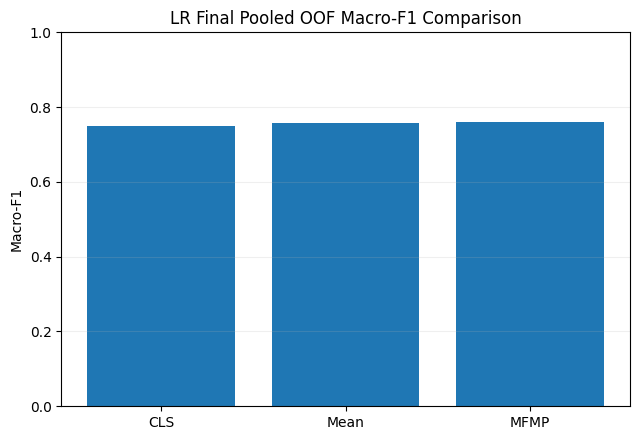

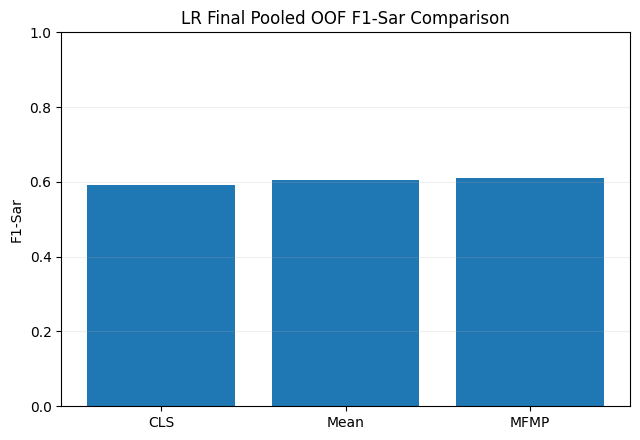

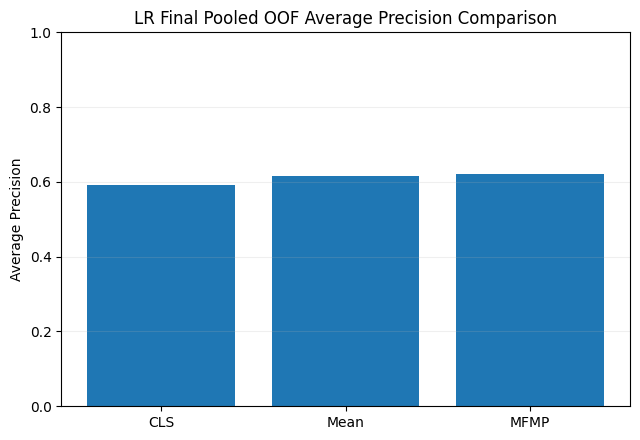

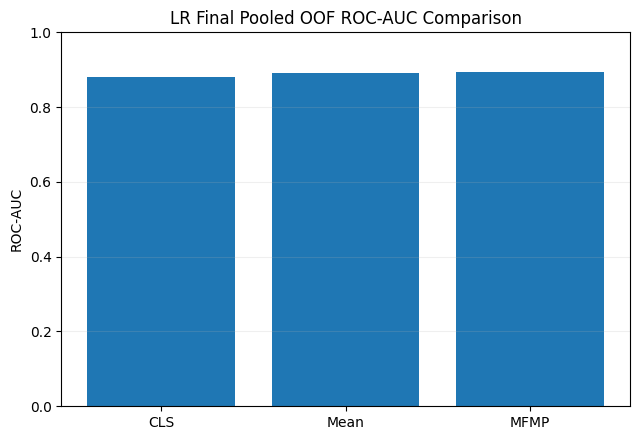

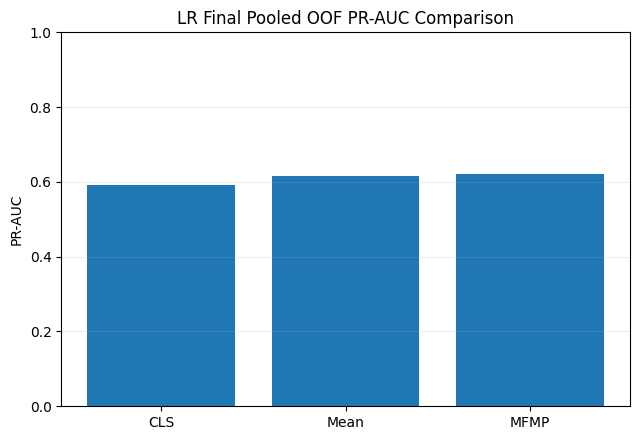

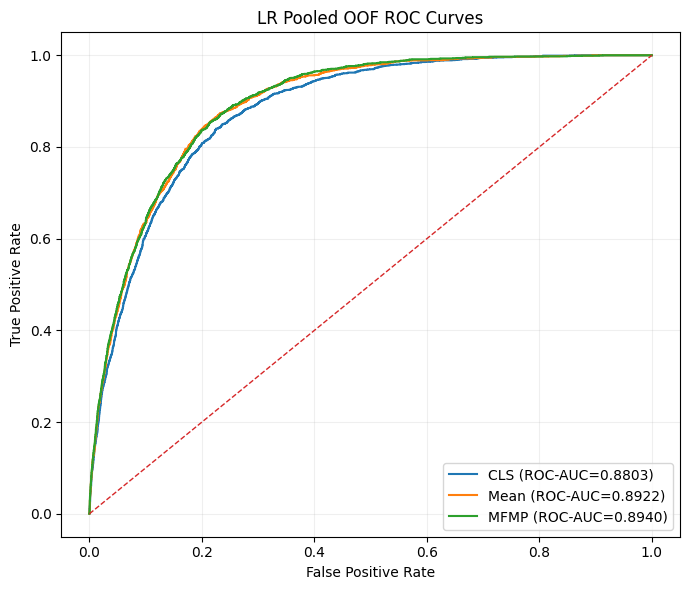

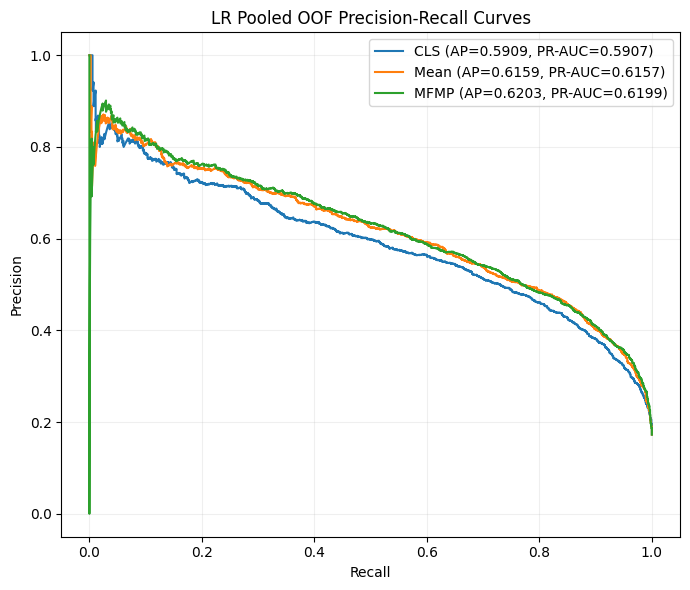

In [21]:
def compact_selected_table(selected_df: pd.DataFrame, classifier: str) -> pd.DataFrame:
    cols = [
        "classifier", "method", "hyperparameters", "K_lower", "K_upper", "selected_threshold",
        "mean_macro_f1", "std_macro_f1", "mean_f1_sarcasm", "mean_recall_sarcasm", "mean_accuracy",
        "macro_f1", "f1_sarcasm", "precision_sarcasm", "recall_sarcasm",
        "roc_auc", "average_precision", "pr_auc",
    ]
    out = selected_df[cols].copy()
    out.insert(0, "label", out["classifier"] + " | " + out["method"])
    return out


def plot_oof_metric_comparisons(selected_df: pd.DataFrame, classifier: str) -> None:
    specs = [
        ("macro_f1", "Macro-F1"),
        ("f1_sarcasm", "F1-Sar"),
        ("average_precision", "Average Precision"),
        ("roc_auc", "ROC-AUC"),
        ("pr_auc", "PR-AUC"),
    ]
    for metric, label in specs:
        fig, ax = plt.subplots(figsize=(6.5, 4.5))
        ax.bar(selected_df["method"], selected_df[metric])
        ax.set_ylim(0, 1)
        ax.set_ylabel(label)
        ax.set_title(f"{classifier} Final Pooled OOF {label} Comparison")
        ax.grid(axis="y", alpha=0.2)
        fig.tight_layout()
        fig.savefig(PLOTS_DIR / f"{classifier.lower()}_oof_{metric}_comparison.png", dpi=300, bbox_inches="tight")
        plt.show()


def plot_oof_curves(oof_score_map: Dict[str, np.ndarray], classifier: str) -> None:
    fig, ax = plt.subplots(figsize=(7, 6))
    for method in ["CLS", "Mean", "MFMP"]:
        fpr, tpr, _ = roc_curve(y_train, oof_score_map[method])
        roc_value = roc_auc_score(y_train, oof_score_map[method])
        ax.plot(fpr, tpr, label=f"{method} (ROC-AUC={roc_value:.4f})")
    ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(f"{classifier} Pooled OOF ROC Curves")
    ax.legend()
    ax.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / f"{classifier.lower()}_oof_roc_curve.png", dpi=300, bbox_inches="tight")
    plt.show()

    fig, ax = plt.subplots(figsize=(7, 6))
    for method in ["CLS", "Mean", "MFMP"]:
        precision, recall, _ = precision_recall_curve(y_train, oof_score_map[method])
        ap = average_precision_score(y_train, oof_score_map[method])
        pr_auc_value = auc(recall[::-1], precision[::-1]) if recall[0] > recall[-1] else auc(recall, precision)
        ax.plot(recall, precision, label=f"{method} (AP={ap:.4f}, PR-AUC={pr_auc_value:.4f})")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.set_title(f"{classifier} Pooled OOF Precision-Recall Curves")
    ax.legend()
    ax.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / f"{classifier.lower()}_oof_pr_curve.png", dpi=300, bbox_inches="tight")
    plt.show()

lr_compact = compact_selected_table(lr_selected, "LR")
display(lr_compact)
plot_oof_metric_comparisons(lr_selected, "LR")
plot_oof_curves(lr_best_oof_scores, "LR")

## 20. SVM Search

**Selection protocol:** every candidate is evaluated with the same fixed **10-fold stratified cross-validation** on TRAIN. In each fold, nine folds are used for training and one fold for validation.

No threshold optimization occurs during candidate comparison. Logistic Regression and Random Forest use `0.5`; Linear SVM uses `0.0` on the decision function.

Candidates are selected by **mean validation Macro-F1**, followed by **mean F1-Sarcasm → mean Recall-Sarcasm → mean Accuracy**. `AP`, `PR-AUC`, and `ROC-AUC` are diagnostic metrics only.

After the best CLS, Mean, and MFMP configuration is fixed, only those three configurations receive an additional pooled 10-fold OOF pass to determine the final operating threshold from TRAIN.

In [22]:
SVM_PARAM_GRID = [{"C": c} for c in SVM_C_VALUES]
print("SVM candidate selection: mean validation Macro-F1 -> mean F1-Sar -> mean Recall-Sar -> mean Accuracy; fixed/default threshold during search.")
svm_search_results, svm_selected, svm_best_oof_scores = search_classifier("SVM", SVM_PARAM_GRID)
svm_search_results.to_csv(METRICS_DIR / "svm_search_results.csv", index=False)
print(f"SVM search complete: {len(svm_search_results)} configurations")
display(svm_selected)

SVM candidate selection: mean validation Macro-F1 -> mean F1-Sar -> mean Recall-Sar -> mean Accuracy; fixed/default threshold during search.
SVM: 64 candidate configurations.
SVM: configuration selection ≈ 64 × 10 = 640 model fits.
SVM: selected configurations require 3 × 10 = 30 additional OOF fits for final threshold selection.


SVM 10-fold CV search: 100%|██████████| 64/64 [18:52<00:00, 17.70s/it]


SVM search complete: 64 configurations


,search_id,classifier,method,K_lower,K_upper,hyperparameters,fold_signature,configuration_selected,selected_threshold,mean_macro_f1,...,precision_sarcasm,recall_sarcasm,f1_sarcasm,balanced_accuracy,mcc,cohen_kappa,tn,fp,fn,tp
0,0,SVM,CLS,NaN,NaN,"{""C"": 0.001}",391a40e39d38fb7057fcf337c190884af9796687065944...,True,0.227411,0.723802,...,0.523525,0.687731,0.594498,0.778499,0.502720,0.495519,9023,1357,677,1491
1,2,SVM,Mean,NaN,NaN,"{""C"": 0.001}",391a40e39d38fb7057fcf337c190884af9796687065944...,True,0.244522,0.729935,...,0.538655,0.690959,0.605375,0.783678,0.516420,0.510283,9097,1283,670,1498
2,18,SVM,MFMP,0.0001,4.0,"{""C"": 0.001}",391a40e39d38fb7057fcf337c190884af9796687065944...,True,0.235867,0.730371,...,0.536577,0.696956,0.606340,0.785617,0.517636,0.510836,9075,1305,657,1511


## 21. SVM Results

,label,classifier,method,hyperparameters,K_lower,K_upper,selected_threshold,mean_macro_f1,std_macro_f1,mean_f1_sarcasm,mean_recall_sarcasm,mean_accuracy,macro_f1,f1_sarcasm,precision_sarcasm,recall_sarcasm,roc_auc,average_precision,pr_auc
0,SVM | CLS,SVM,CLS,"{""C"": 0.001}",NaN,NaN,0.227411,0.723802,0.011604,0.580621,0.809022,0.798056,0.746601,0.594498,0.523525,0.687731,0.877878,0.581092,0.580865
1,SVM | Mean,SVM,Mean,"{""C"": 0.001}",NaN,NaN,0.244522,0.729935,0.010555,0.590112,0.822879,0.802361,0.754219,0.605375,0.538655,0.690959,0.886275,0.603113,0.602854
2,SVM | MFMP,SVM,MFMP,"{""C"": 0.001}",0.0001,4.0,0.235867,0.730371,0.010571,0.590765,0.823805,0.802680,0.754393,0.606340,0.536577,0.696956,0.886229,0.603581,0.603344


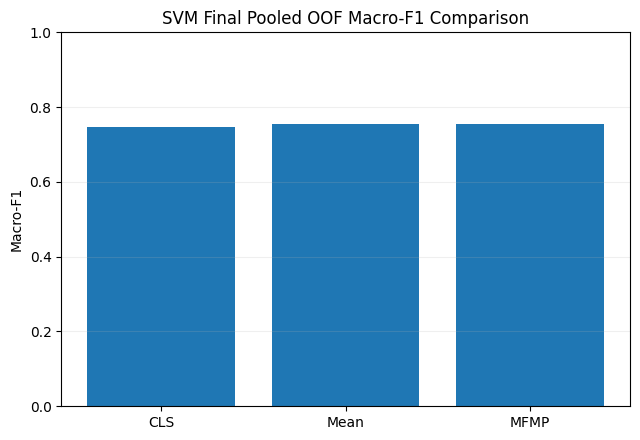

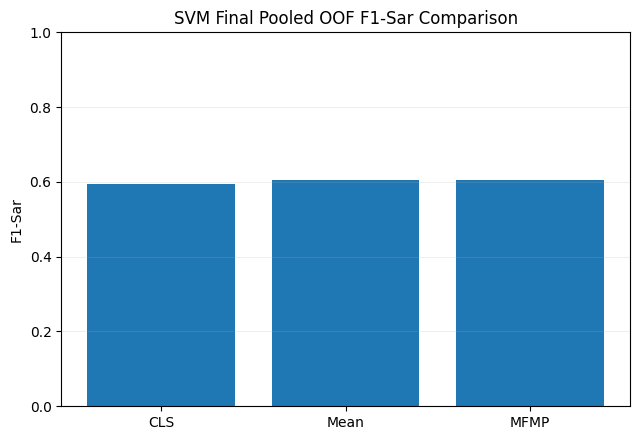

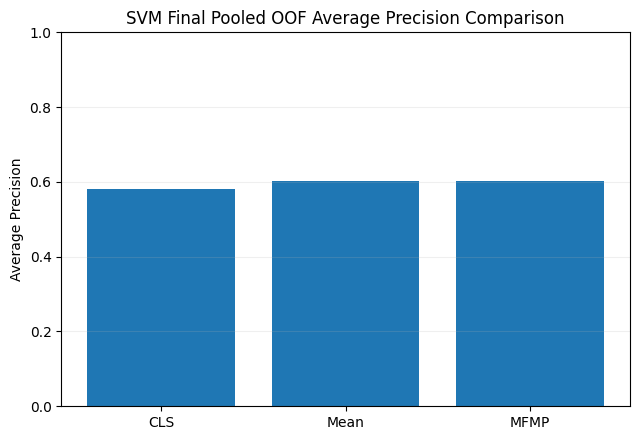

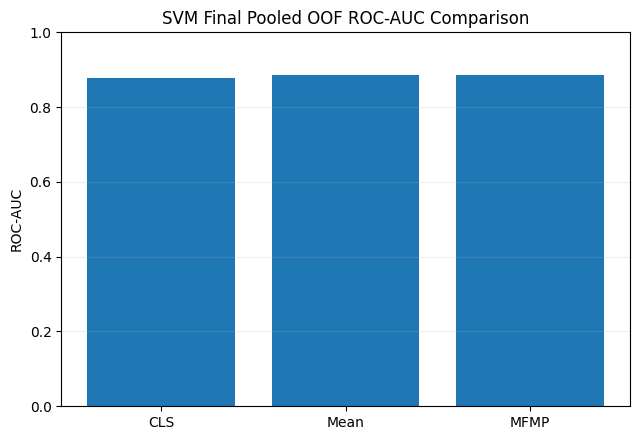

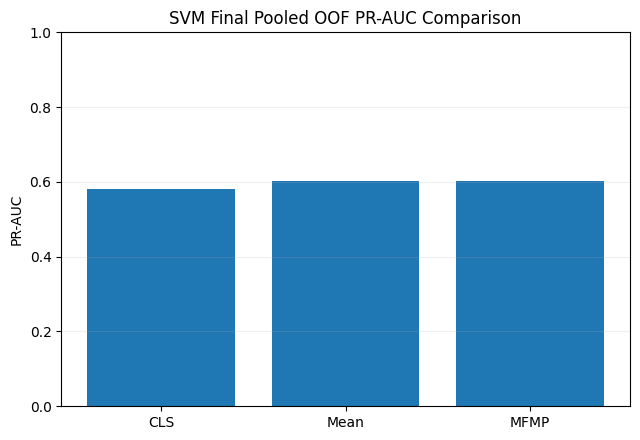

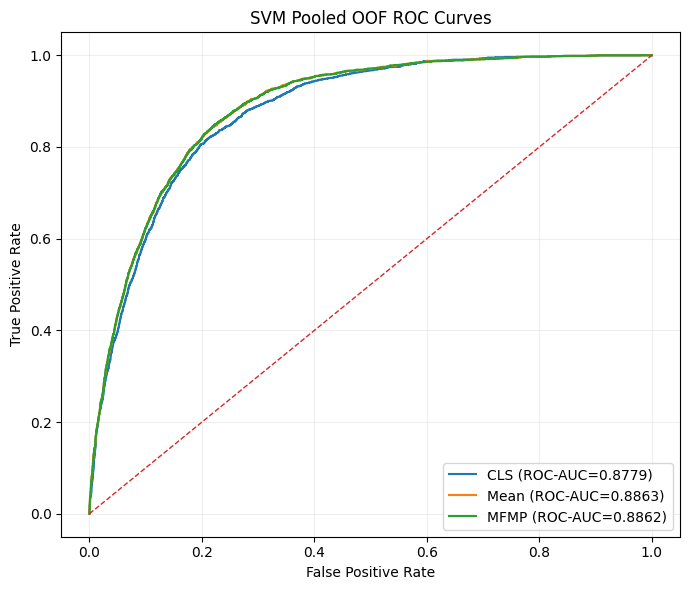

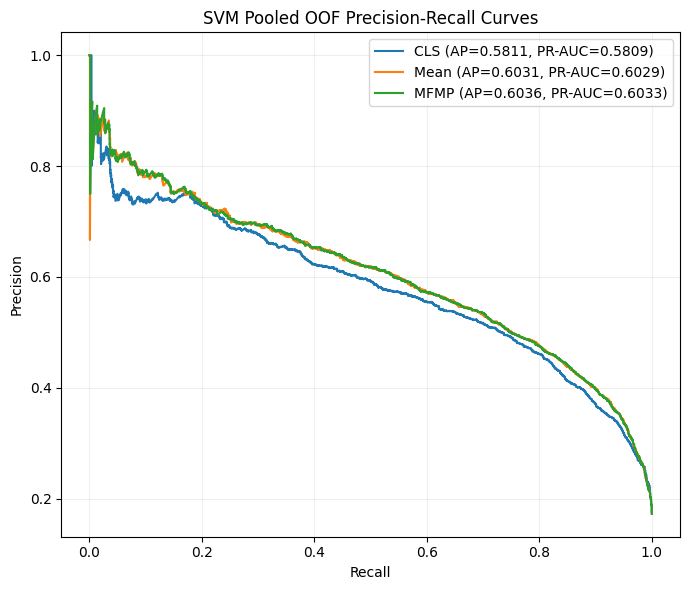

In [23]:
svm_compact = compact_selected_table(svm_selected, "SVM")
display(svm_compact)
plot_oof_metric_comparisons(svm_selected, "SVM")
plot_oof_curves(svm_best_oof_scores, "SVM")

## 22. Random Forest Search

**Selection protocol:** every candidate is evaluated with the same fixed **10-fold stratified cross-validation** on TRAIN. In each fold, nine folds are used for training and one fold for validation.

No threshold optimization occurs during candidate comparison. Logistic Regression and Random Forest use `0.5`; Linear SVM uses `0.0` on the decision function.

Candidates are selected by **mean validation Macro-F1**, followed by **mean F1-Sarcasm → mean Recall-Sarcasm → mean Accuracy**. `AP`, `PR-AUC`, and `ROC-AUC` are diagnostic metrics only.

After the best CLS, Mean, and MFMP configuration is fixed, only those three configurations receive an additional pooled 10-fold OOF pass to determine the final operating threshold from TRAIN.

In [25]:
print("RF candidate selection: mean validation Macro-F1 -> mean F1-Sar -> mean Recall-Sar -> mean Accuracy; fixed/default threshold during search.")
print("RF parameter combinations (computed):", len(RF_COMBINATIONS))
if len(RF_COMBINATIONS) != 2:
    raise RuntimeError(f"Expected 8 RF parameter combinations from RF_PARAM_GRID, found {len(RF_COMBINATIONS)}")

rf_search_results, rf_selected, rf_best_oof_scores = search_classifier("RF", RF_COMBINATIONS)
rf_search_results.to_csv(METRICS_DIR / "rf_search_results.csv", index=False)
print(f"RF search complete: {len(rf_search_results)} configurations")
display(rf_selected)

RF candidate selection: mean validation Macro-F1 -> mean F1-Sar -> mean Recall-Sar -> mean Accuracy; fixed/default threshold during search.
RF parameter combinations (computed): 2
RF: 64 candidate configurations.
RF: configuration selection ≈ 64 × 10 = 640 model fits.
RF: selected configurations require 3 × 10 = 30 additional OOF fits for final threshold selection.


RF 10-fold CV search: 100%|██████████| 64/64 [2:26:12<00:00, 137.08s/it]  


RF search complete: 64 configurations


,search_id,classifier,method,K_lower,K_upper,hyperparameters,fold_signature,configuration_selected,selected_threshold,mean_macro_f1,...,precision_sarcasm,recall_sarcasm,f1_sarcasm,balanced_accuracy,mcc,cohen_kappa,tn,fp,fn,tp
0,1,RF,CLS,NaN,NaN,"{""class_weight"": ""balanced_subsample"", ""max_de...",391a40e39d38fb7057fcf337c190884af9796687065944...,True,0.249452,0.609753,...,0.463208,0.630074,0.533907,0.738784,0.425808,0.418004,8797,1583,802,1366
1,3,RF,Mean,NaN,NaN,"{""class_weight"": ""balanced_subsample"", ""max_de...",391a40e39d38fb7057fcf337c190884af9796687065944...,True,0.272248,0.617080,...,0.507439,0.597786,0.548920,0.738296,0.447501,0.445234,9122,1258,872,1296
2,49,RF,MFMP,0.01,1.5,"{""class_weight"": ""balanced_subsample"", ""max_de...",391a40e39d38fb7057fcf337c190884af9796687065944...,True,0.266275,0.630280,...,0.510471,0.629613,0.563817,0.751752,0.464841,0.460948,9071,1309,803,1365


## 23. Random Forest Results

,label,classifier,method,hyperparameters,K_lower,K_upper,selected_threshold,mean_macro_f1,std_macro_f1,mean_f1_sarcasm,mean_recall_sarcasm,mean_accuracy,macro_f1,f1_sarcasm,precision_sarcasm,recall_sarcasm,roc_auc,average_precision,pr_auc
0,RF | CLS,RF,CLS,"{""class_weight"": ""balanced_subsample"", ""max_de...",NaN,NaN,0.249452,0.609753,0.026097,0.307900,0.202511,0.843243,0.707266,0.533907,0.463208,0.630074,0.834269,0.503632,0.503147
1,RF | Mean,RF,Mean,"{""class_weight"": ""balanced_subsample"", ""max_de...",NaN,NaN,0.272248,0.617080,0.026005,0.321465,0.213117,0.845315,0.722187,0.548920,0.507439,0.597786,0.853358,0.526881,0.526368
2,RF | MFMP,RF,MFMP,"{""class_weight"": ""balanced_subsample"", ""max_de...",0.01,1.5,0.266275,0.630280,0.025302,0.346448,0.233412,0.848184,0.729770,0.563817,0.510471,0.629613,0.867171,0.546605,0.546141


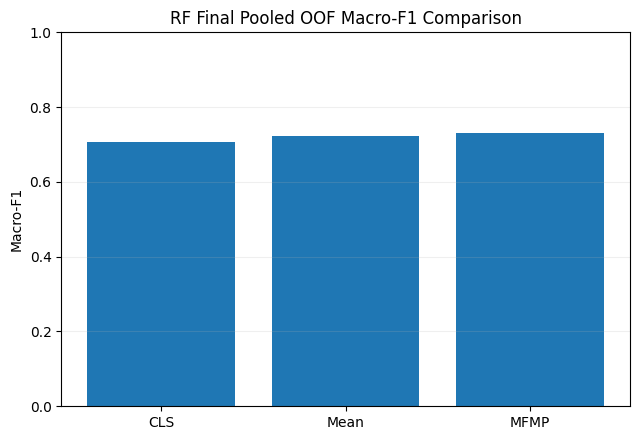

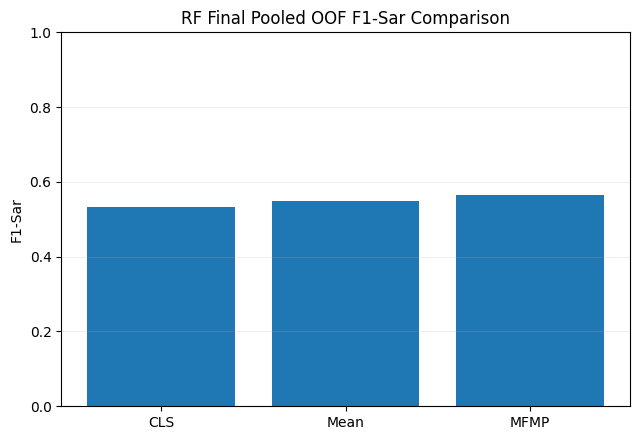

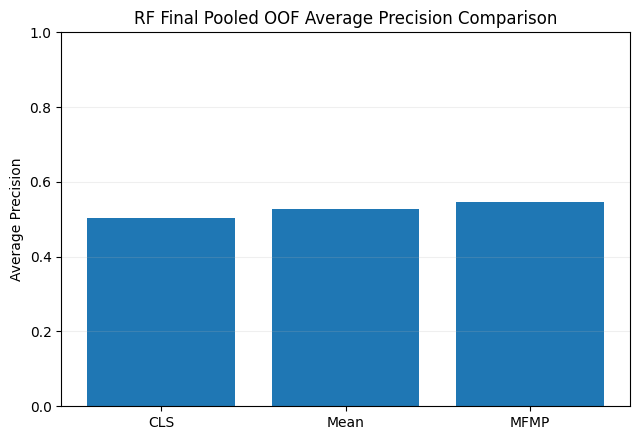

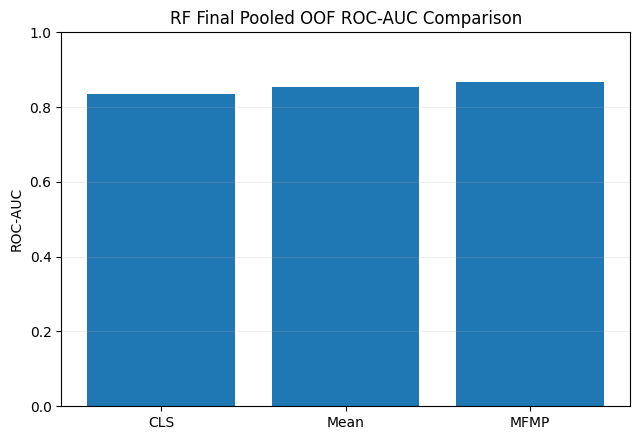

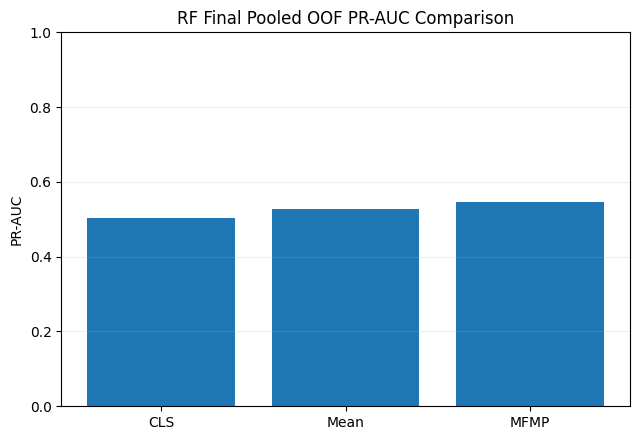

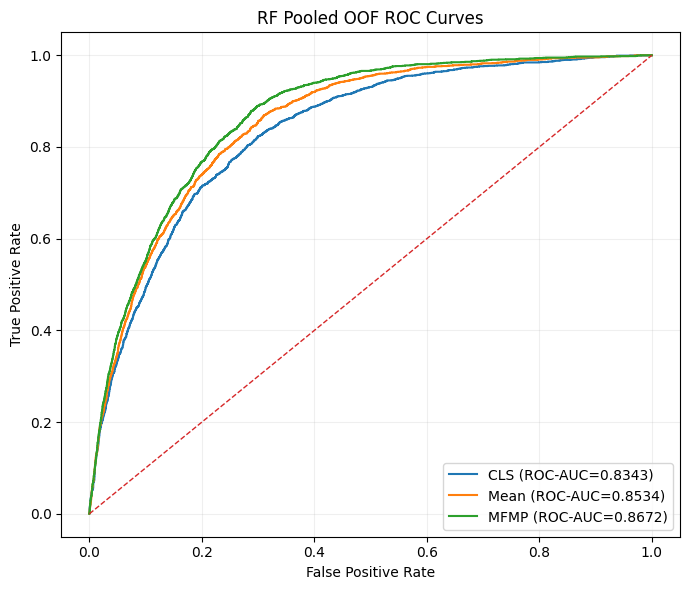

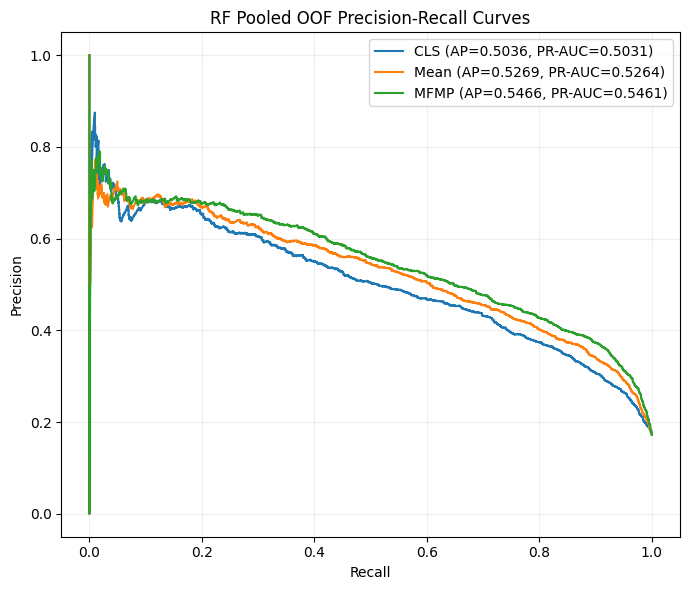

In [26]:
rf_compact = compact_selected_table(rf_selected, "RF")
display(rf_compact)
plot_oof_metric_comparisons(rf_selected, "RF")
plot_oof_curves(rf_best_oof_scores, "RF")

## 24. Final Test Evaluation

In [27]:
# Consolidate current 10-fold CV candidate-search results before touching TEST labels.
all_oof_search_results = pd.concat(
    [lr_search_results, svm_search_results, rf_search_results],
    ignore_index=True,
)
all_oof_search_results.to_csv(
    METRICS_DIR / "all_oof_search_results.csv",
    index=False,
)

selected_configurations = pd.concat(
    [lr_selected, svm_selected, rf_selected],
    ignore_index=True,
)
selected_configurations.to_csv(
    METRICS_DIR / "selected_configurations.csv",
    index=False,
)

# TEST labels become available only now, after TRAIN-only candidate selection
# and final OOF threshold selection for the already-selected configurations.
y_test = test_df[LABEL_COLUMN].to_numpy(dtype=np.int64)

# Data leakage guard: selection objects are fully determined from TRAIN OOF results above.
assert set(selected_configurations["classifier"]) == {"LR", "SVM", "RF"}
assert len(selected_configurations) == 9
assert selected_configurations.groupby("classifier")["method"].nunique().eq(3).all()

FINAL_TEST_SCORE_MAP: Dict[Tuple[str, str], np.ndarray] = {}
FINAL_TEST_PRED_MAP: Dict[Tuple[str, str], np.ndarray] = {}
final_rows: List[Dict[str, Any]] = []

for selected in selected_configurations.to_dict("records"):
    classifier = selected["classifier"]
    method = selected["method"]
    kl = None if pd.isna(selected["K_lower"]) else float(selected["K_lower"])
    ku = None if pd.isna(selected["K_upper"]) else float(selected["K_upper"])
    params = json.loads(selected["hyperparameters"])
    threshold = float(selected["selected_threshold"])

    X_train_rep = load_representation("train", method, kl, ku)
    X_test_rep = load_representation("test", method, kl, ku)
    assert X_train_rep.shape[0] == len(y_train)
    assert X_test_rep.shape[0] == len(y_test)

    estimator = build_estimator(classifier, params)
    # For LR/SVM, Pipeline.fit here fits StandardScaler on FULL TRAIN only. TEST remains untouched until transform/prediction.
    estimator.fit(X_train_rep, y_train)
    test_scores = continuous_scores(estimator, classifier, X_test_rep)
    test_predictions = (test_scores >= threshold).astype(np.int64)
    test_metrics = calculate_metrics(y_test, test_scores, threshold)

    if method == "MFMP":
        token_row = k_token_statistics[
            (k_token_statistics["split"] == "Test") &
            np.isclose(k_token_statistics["K_lower"], kl) &
            np.isclose(k_token_statistics["K_upper"], ku)
        ]
        if len(token_row) != 1:
            raise RuntimeError(f"Could not uniquely resolve TEST MFMP token stats for K=({kl},{ku})")
        excluded_tokens = int(token_row.iloc[0]["excluded_tokens"])
        excluded_pct = float(token_row.iloc[0]["excluded_percentage"])
    else:
        excluded_tokens = 0
        excluded_pct = 0.0

    result_row = {
        "Classifier": classifier,
        "Approach": method,
        "Best Parameters": json.dumps(params, sort_keys=True),
        "K_lower": kl,
        "K_upper": ku,
        "Threshold": threshold,
        "Accuracy": test_metrics["accuracy"],
        "Macro-Precision": test_metrics["macro_precision"],
        "Macro-Recall": test_metrics["macro_recall"],
        "Macro-F1": test_metrics["macro_f1"],
        "Precision-Sar": test_metrics["precision_sarcasm"],
        "Recall-Sar": test_metrics["recall_sarcasm"],
        "F1-Sar": test_metrics["f1_sarcasm"],
        "Precision-NonSar": test_metrics["precision_non_sarcasm"],
        "Recall-NonSar": test_metrics["recall_non_sarcasm"],
        "F1-NonSar": test_metrics["f1_non_sarcasm"],
        "Balanced Accuracy": test_metrics["balanced_accuracy"],
        "MCC": test_metrics["mcc"],
        "Cohen Kappa": test_metrics["cohen_kappa"],
        "ROC-AUC": test_metrics["roc_auc"],
        "Average Precision": test_metrics["average_precision"],
        "PR-AUC": test_metrics["pr_auc"],
        "TN": test_metrics["tn"], "FP": test_metrics["fp"], "FN": test_metrics["fn"], "TP": test_metrics["tp"],
        "Excluded Tokens": excluded_tokens,
        "Excluded %": excluded_pct,
    }
    final_rows.append(result_row)
    FINAL_TEST_SCORE_MAP[(classifier, method)] = test_scores.copy()
    FINAL_TEST_PRED_MAP[(classifier, method)] = test_predictions.copy()

    pred_df = pd.DataFrame({
        "row_id": test_df["row_id"].to_numpy(),
        "text": test_df[TEXT_COLUMN].to_numpy(),
        "true_label": y_test,
        "continuous_score": test_scores,
        "threshold": threshold,
        "predicted_label": test_predictions,
        "correct": test_predictions == y_test,
    })
    pred_df.to_csv(PREDICTIONS_DIR / f"{classifier}_{method}_test_predictions.csv", index=False)

    del estimator, X_train_rep, X_test_rep
    gc.collect()

final_test_results = pd.DataFrame(final_rows)
final_test_results.to_csv(METRICS_DIR / "final_test_results.csv", index=False)
final_test_results.to_excel(METRICS_DIR / "final_test_results.xlsx", index=False)
display(final_test_results)

,Classifier,Approach,Best Parameters,K_lower,K_upper,Threshold,Accuracy,Macro-Precision,Macro-Recall,Macro-F1,...,Cohen Kappa,ROC-AUC,Average Precision,PR-AUC,TN,FP,FN,TP,Excluded Tokens,Excluded %
0,LR,CLS,"{""C"": 0.001}",NaN,NaN,0.698729,0.767000,0.709896,0.721186,0.714846,...,0.430127,0.813232,0.604841,0.604318,1792,387,312,509,0,0.000000
1,LR,Mean,"{""C"": 0.001}",NaN,NaN,0.729826,0.771333,0.712460,0.712782,0.712621,...,0.425241,0.823032,0.609138,0.608657,1835,344,342,479,0,0.000000
2,LR,MFMP,"{""C"": 0.001}",0.0001,1.5,0.708443,0.766667,0.709544,0.720956,0.714537,...,0.429522,0.825731,0.617637,0.617177,1791,388,312,509,5690,8.509556
3,SVM,CLS,"{""C"": 0.001}",NaN,NaN,0.227411,0.760000,0.706398,0.728513,0.714467,...,0.430860,0.814860,0.599472,0.598683,1739,440,280,541,0,0.000000
4,SVM,Mean,"{""C"": 0.001}",NaN,NaN,0.244522,0.765333,0.713188,0.737498,0.721864,...,0.445887,0.820324,0.592778,0.592197,1741,438,266,555,0,0.000000
5,SVM,MFMP,"{""C"": 0.001}",0.0001,4.0,0.235867,0.761333,0.709718,0.735503,0.718520,...,0.439636,0.818303,0.588965,0.588308,1727,452,264,557,717,1.072294
6,RF,CLS,"{""class_weight"": ""balanced_subsample"", ""max_de...",NaN,NaN,0.249452,0.743000,0.684586,0.700489,0.690763,...,0.382816,0.785339,0.585157,0.584760,1731,448,323,498,0,0.000000
7,RF,Mean,"{""class_weight"": ""balanced_subsample"", ""max_de...",NaN,NaN,0.272248,0.754000,0.693886,0.703127,0.697984,...,0.396327,0.797315,0.590880,0.590344,1777,402,336,485,0,0.000000
8,RF,MFMP,"{""class_weight"": ""balanced_subsample"", ""max_de...",0.0100,1.5,0.266275,0.756333,0.696739,0.706252,0.700954,...,0.402274,0.803323,0.598281,0.597605,1780,399,332,489,6016,8.997099


## 25. ROC Curves

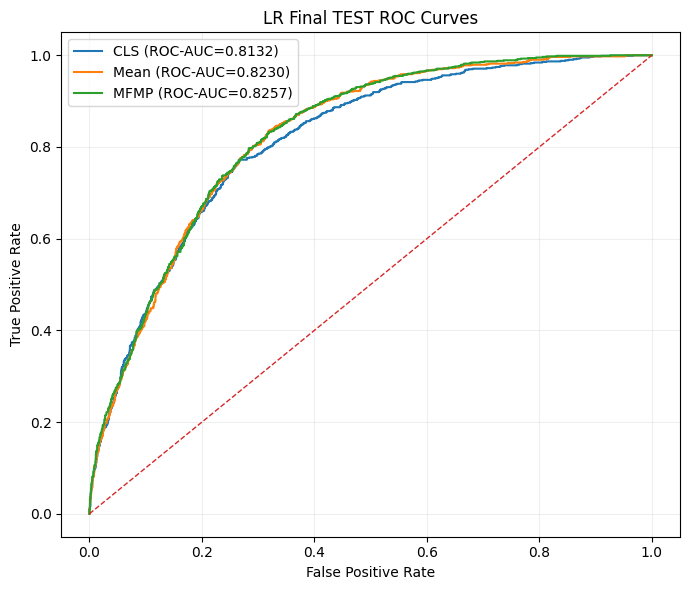

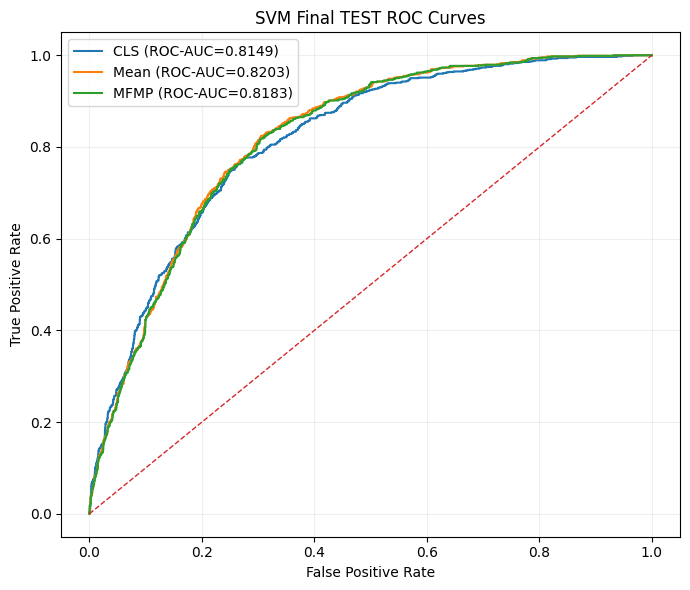

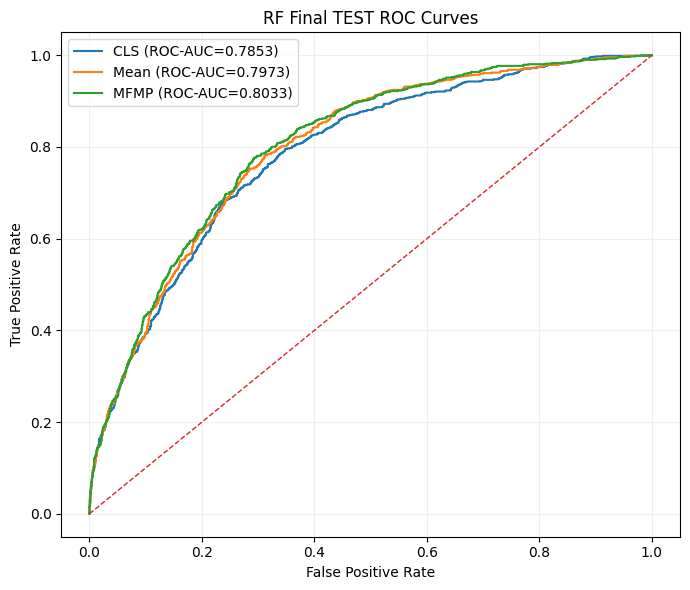

In [28]:
def plot_final_roc(classifier: str) -> None:
    fig, ax = plt.subplots(figsize=(7, 6))
    for method in ["CLS", "Mean", "MFMP"]:
        scores = FINAL_TEST_SCORE_MAP[(classifier, method)]
        fpr, tpr, _ = roc_curve(y_test, scores)
        roc_value = roc_auc_score(y_test, scores)
        ax.plot(fpr, tpr, label=f"{method} (ROC-AUC={roc_value:.4f})")
    ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(f"{classifier} Final TEST ROC Curves")
    ax.legend()
    ax.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / f"{classifier.lower()}_roc_curve.png", dpi=300, bbox_inches="tight")
    plt.show()

for clf in ["LR", "SVM", "RF"]:
    plot_final_roc(clf)

## 26. Precision-Recall Curves

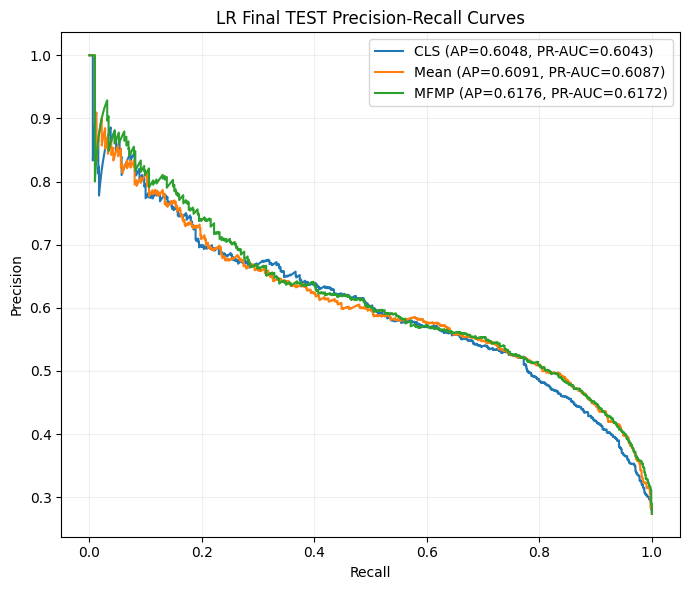

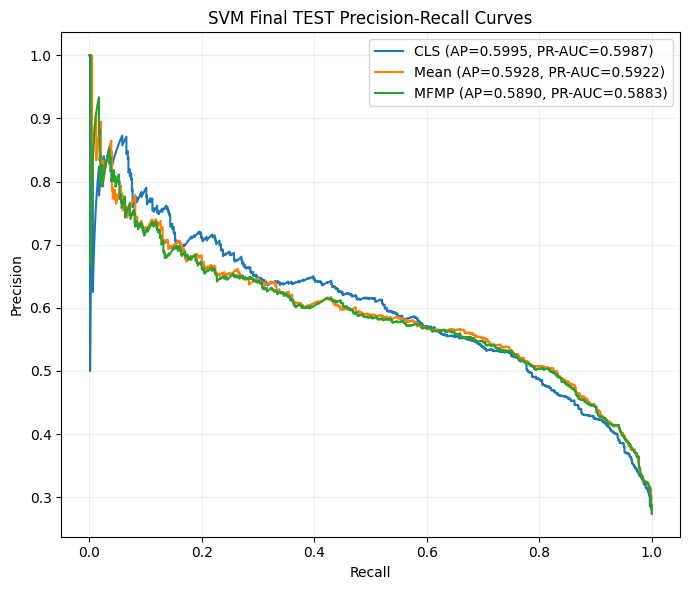

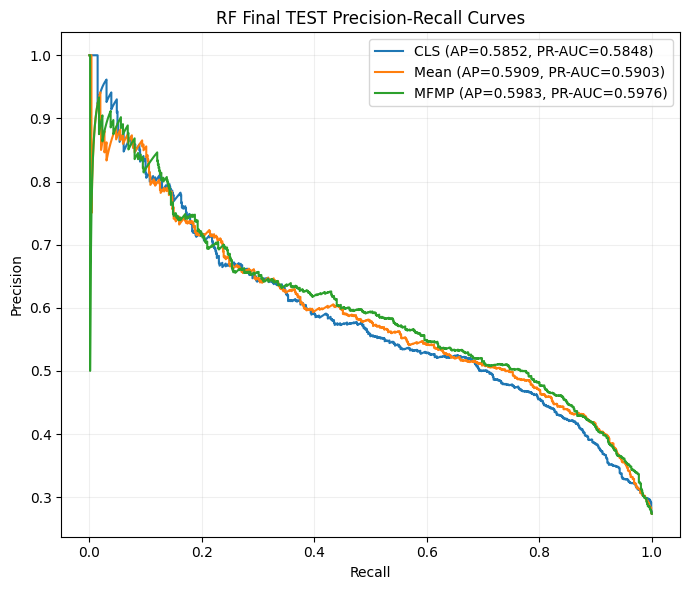

In [29]:
def plot_final_pr(classifier: str) -> None:
    fig, ax = plt.subplots(figsize=(7, 6))
    for method in ["CLS", "Mean", "MFMP"]:
        scores = FINAL_TEST_SCORE_MAP[(classifier, method)]
        precision, recall, _ = precision_recall_curve(y_test, scores)
        ap = average_precision_score(y_test, scores)
        pr_auc_value = auc(recall[::-1], precision[::-1]) if recall[0] > recall[-1] else auc(recall, precision)
        ax.plot(recall, precision, label=f"{method} (AP={ap:.4f}, PR-AUC={pr_auc_value:.4f})")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.set_title(f"{classifier} Final TEST Precision-Recall Curves")
    ax.legend()
    ax.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / f"{classifier.lower()}_pr_curve.png", dpi=300, bbox_inches="tight")
    plt.show()

for clf in ["LR", "SVM", "RF"]:
    plot_final_pr(clf)

## 27. Confusion Matrices

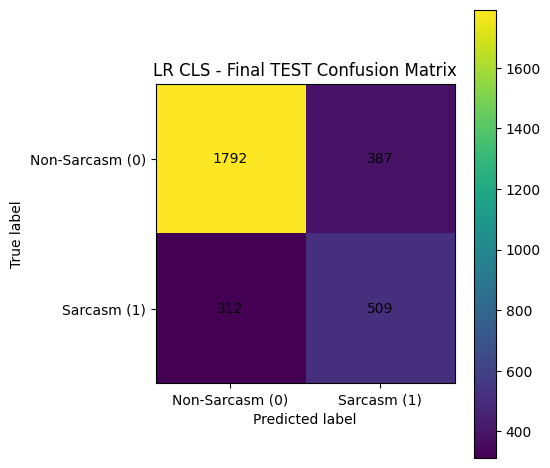

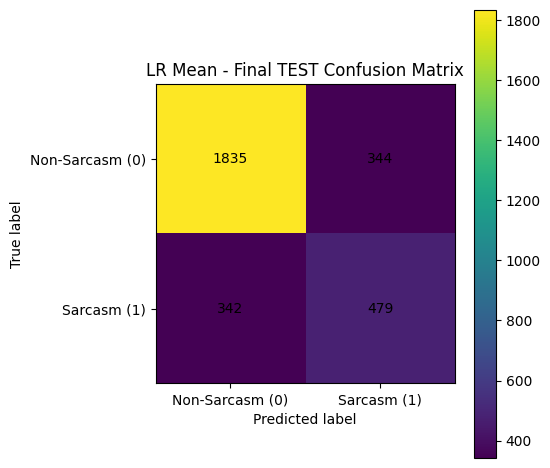

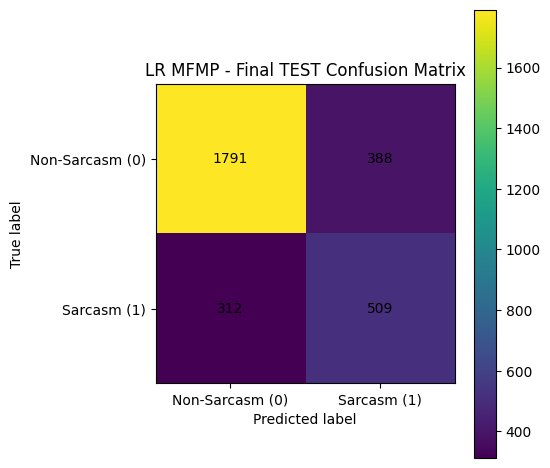

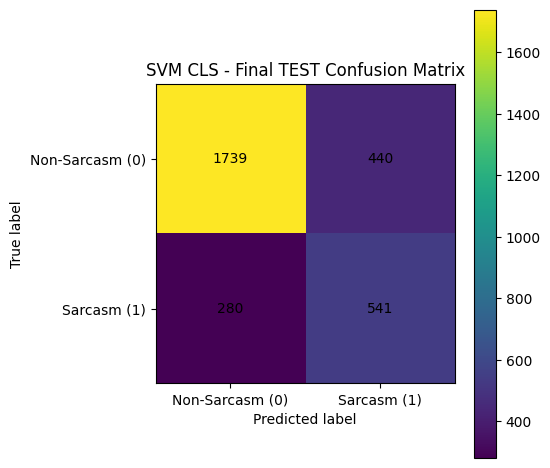

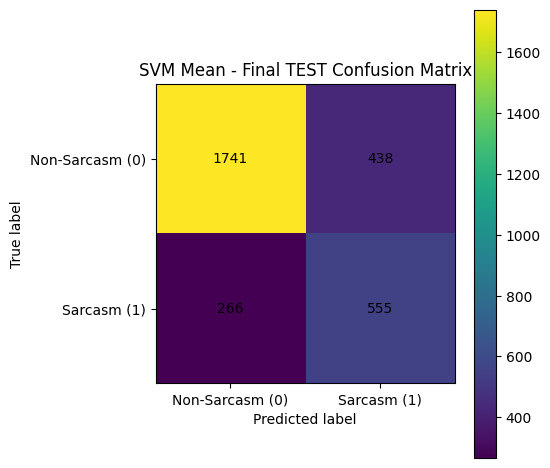

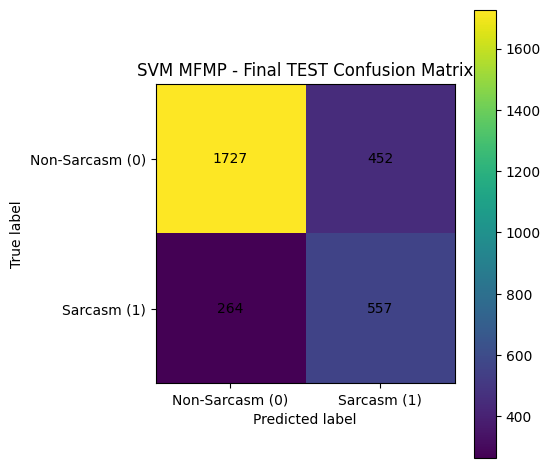

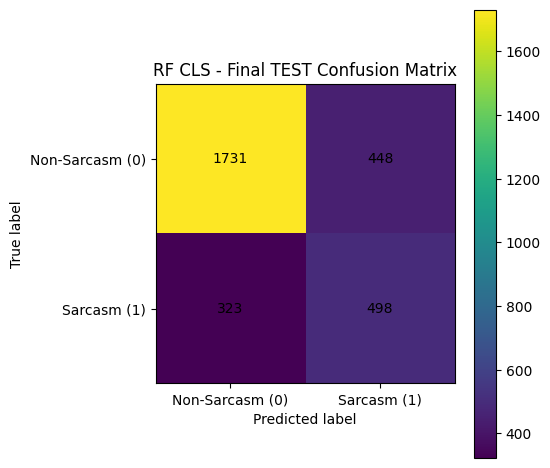

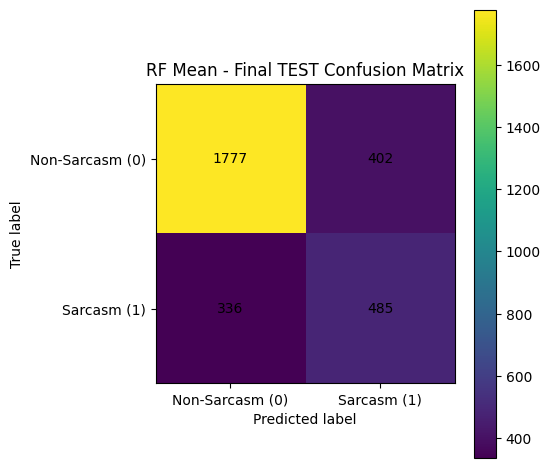

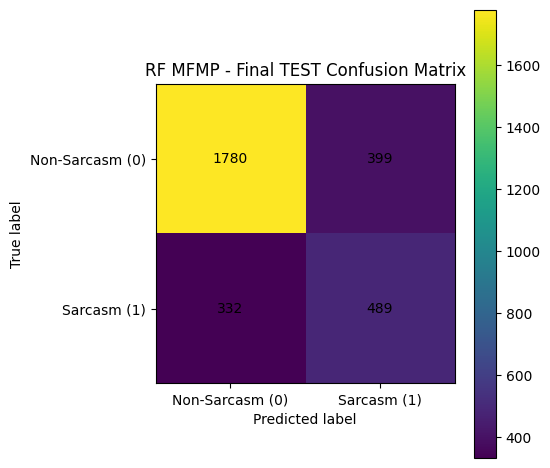

In [30]:
def plot_confusion_matrix(classifier: str, method: str) -> None:
    preds = FINAL_TEST_PRED_MAP[(classifier, method)]
    cm = confusion_matrix(y_test, preds, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(5.5, 5))
    im = ax.imshow(cm)
    ax.set_xticks([0, 1], ["Non-Sarcasm (0)", "Sarcasm (1)"])
    ax.set_yticks([0, 1], ["Non-Sarcasm (0)", "Sarcasm (1)"])
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_title(f"{classifier} {method} - Final TEST Confusion Matrix")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")
    fig.colorbar(im, ax=ax)
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / f"confusion_matrix_{classifier}_{method}.png", dpi=300, bbox_inches="tight")
    plt.show()

for clf in ["LR", "SVM", "RF"]:
    for method in ["CLS", "Mean", "MFMP"]:
        plot_confusion_matrix(clf, method)

## 28. MFMP Token Statistics

In [31]:
best_mfmp_rows = []
for classifier in ["LR", "SVM", "RF"]:
    selected = selected_configurations[
        (selected_configurations["classifier"] == classifier) &
        (selected_configurations["method"] == "MFMP")
    ].iloc[0]
    kl, ku = float(selected["K_lower"]), float(selected["K_upper"])
    for split in ["Train", "Test"]:
        token_row = k_token_statistics[
            (k_token_statistics["split"] == split) &
            np.isclose(k_token_statistics["K_lower"], kl) &
            np.isclose(k_token_statistics["K_upper"], ku)
        ].iloc[0]
        best_mfmp_rows.append({
            "classifier": classifier,
            "split": split,
            "K_lower": kl,
            "K_upper": ku,
            "total_valid_tokens": int(token_row["total_valid_tokens"]),
            "retained_tokens": int(token_row["retained_tokens"]),
            "excluded_tokens": int(token_row["excluded_tokens"]),
            "excluded_percentage": float(token_row["excluded_percentage"]),
            "fallback_sentences": int(token_row["fallback_sentences"]),
        })

best_mfmp_token_statistics = pd.DataFrame(best_mfmp_rows)
best_mfmp_token_statistics.to_csv(TABLES_DIR / "best_mfmp_token_statistics.csv", index=False)
display(best_mfmp_token_statistics)

# |z| zones are computed before K filtering, therefore the zone distribution is K-independent.
# Expand it by each classifier's selected MFMP K so the final audit table is self-contained.
best_zone_rows = []
for classifier in ["LR", "SVM", "RF"]:
    selected = selected_configurations[(selected_configurations["classifier"] == classifier) & (selected_configurations["method"] == "MFMP")].iloc[0]
    kl, ku = float(selected["K_lower"]), float(selected["K_upper"])
    for zone_row in absolute_z_zone_distribution.to_dict("records"):
        best_zone_rows.append({
            "classifier": classifier, "K_lower": kl, "K_upper": ku,
            "split": zone_row["split"], "zone": zone_row["zone"],
            "count": int(zone_row["count"]), "percentage": float(zone_row["percentage"]),
        })
best_mfmp_zone_distribution = pd.DataFrame(best_zone_rows)
best_mfmp_zone_distribution.to_csv(TABLES_DIR / "best_mfmp_absolute_z_zone_distribution.csv", index=False)
display(best_mfmp_zone_distribution.head(12))


,classifier,split,K_lower,K_upper,total_valid_tokens,retained_tokens,excluded_tokens,excluded_percentage,fallback_sentences
0,LR,Train,0.0001,1.5,242117,217841,24276,10.026557,0
1,LR,Test,0.0001,1.5,66866,61176,5690,8.509556,0
2,SVM,Train,0.0001,4.0,242117,241525,592,0.244510,0
3,SVM,Test,0.0001,4.0,66866,66149,717,1.072294,0
4,RF,Train,0.0100,1.5,242117,217305,24812,10.247938,0
5,RF,Test,0.0100,1.5,66866,60850,6016,8.997099,0


,classifier,K_lower,K_upper,split,zone,count,percentage
0,LR,0.0001,1.5,Train,0-0.5,204548,84.483122
1,LR,0.0001,1.5,Train,0.5-1,12482,5.155359
2,LR,0.0001,1.5,Train,1-1.5,813,0.335788
3,LR,0.0001,1.5,Train,1.5-2,2790,1.152335
4,LR,0.0001,1.5,Train,2-2.5,4285,1.769806
5,LR,0.0001,1.5,Train,2.5-3,6307,2.604939
6,LR,0.0001,1.5,Train,3-3.5,6360,2.626829
7,LR,0.0001,1.5,Train,3.5-4,3942,1.628138
8,LR,0.0001,1.5,Train,4-4.5,320,0.132168
9,LR,0.0001,1.5,Train,4.5-5,170,0.070214


## 29. Final Comparison Table

In [32]:
# Preserve all 9 methods; sort only for presentation.
final_comparison = final_test_results.sort_values(
    ["Classifier", "Macro-F1"], ascending=[True, False], kind="mergesort"
).reset_index(drop=True)
display(final_comparison)

,Classifier,Approach,Best Parameters,K_lower,K_upper,Threshold,Accuracy,Macro-Precision,Macro-Recall,Macro-F1,...,Cohen Kappa,ROC-AUC,Average Precision,PR-AUC,TN,FP,FN,TP,Excluded Tokens,Excluded %
0,LR,CLS,"{""C"": 0.001}",NaN,NaN,0.698729,0.767000,0.709896,0.721186,0.714846,...,0.430127,0.813232,0.604841,0.604318,1792,387,312,509,0,0.000000
1,LR,MFMP,"{""C"": 0.001}",0.0001,1.5,0.708443,0.766667,0.709544,0.720956,0.714537,...,0.429522,0.825731,0.617637,0.617177,1791,388,312,509,5690,8.509556
2,LR,Mean,"{""C"": 0.001}",NaN,NaN,0.729826,0.771333,0.712460,0.712782,0.712621,...,0.425241,0.823032,0.609138,0.608657,1835,344,342,479,0,0.000000
3,RF,MFMP,"{""class_weight"": ""balanced_subsample"", ""max_de...",0.0100,1.5,0.266275,0.756333,0.696739,0.706252,0.700954,...,0.402274,0.803323,0.598281,0.597605,1780,399,332,489,6016,8.997099
4,RF,Mean,"{""class_weight"": ""balanced_subsample"", ""max_de...",NaN,NaN,0.272248,0.754000,0.693886,0.703127,0.697984,...,0.396327,0.797315,0.590880,0.590344,1777,402,336,485,0,0.000000
5,RF,CLS,"{""class_weight"": ""balanced_subsample"", ""max_de...",NaN,NaN,0.249452,0.743000,0.684586,0.700489,0.690763,...,0.382816,0.785339,0.585157,0.584760,1731,448,323,498,0,0.000000
6,SVM,Mean,"{""C"": 0.001}",NaN,NaN,0.244522,0.765333,0.713188,0.737498,0.721864,...,0.445887,0.820324,0.592778,0.592197,1741,438,266,555,0,0.000000
7,SVM,MFMP,"{""C"": 0.001}",0.0001,4.0,0.235867,0.761333,0.709718,0.735503,0.718520,...,0.439636,0.818303,0.588965,0.588308,1727,452,264,557,717,1.072294
8,SVM,CLS,"{""C"": 0.001}",NaN,NaN,0.227411,0.760000,0.706398,0.728513,0.714467,...,0.430860,0.814860,0.599472,0.598683,1739,440,280,541,0,0.000000


## 30. Experiment Summary

In [33]:
# Final leakage/integrity assertions.

for clf_name, search_df, selected_df in [
    ("LR", lr_search_results, lr_selected),
    ("SVM", svm_search_results, svm_selected),
    ("RF", rf_search_results, rf_selected),
]:
    assert int(search_df["configuration_selected"].sum()) == 3
    assert selected_df["selected_threshold"].notna().all()

    assert search_df[
        ["average_precision", "pr_auc", "roc_auc"]
    ].notna().all().all()

    expected_candidate_threshold = 0.0 if clf_name == "SVM" else 0.5
    assert np.allclose(
        search_df["candidate_threshold"],
        expected_candidate_threshold,
    )

    for method_name in ["CLS", "Mean", "MFMP"]:
        method_rows = search_df[search_df["method"] == method_name]
        expected = method_rows.sort_values(
            [
                "mean_macro_f1",
                "mean_f1_sarcasm",
                "mean_recall_sarcasm",
                "mean_accuracy",
                "search_id",
            ],
            ascending=[False, False, False, False, True],
            kind="mergesort",
        ).iloc[0]
        actual = selected_df[selected_df["method"] == method_name].iloc[0]
        assert int(expected["search_id"]) == int(actual["search_id"])

assert np.all(fold_id >= 0)
assert len(fold_id) == len(train_df)
assert all_oof_search_results["fold_signature"].nunique() == 1
assert all_oof_search_results["fold_signature"].iloc[0] == FOLD_SIGNATURE

assert set(train_df["row_key"]).isdisjoint(set(test_df["row_key"]))

for split, df, y in [
    ("train", train_df, y_train),
    ("test", test_df, y_test),
]:
    assert len(df) == len(y)
    assert load_representation(split, "CLS").shape[0] == len(y)
    assert load_representation(split, "Mean").shape[0] == len(y)

print("================ FINAL EXPERIMENT SUMMARY ================")
print("\nDataset:")
print(f"Train: {len(train_df):,}")
print(f"Test:  {len(test_df):,}")
print("Class distribution:")
print(dataset_summary.to_string(index=False))
print("\nMARBERTv2:")
print(f"Model path: {MODEL_PATH.relative_to(PROJECT_ROOT)}")
print(f"Max length: {MAX_LEN}")
print("\nCV:")
print(f"{CV_FOLDS}-fold Stratified CV for configuration selection")
print("Candidate thresholds: LR/RF=0.5, SVM=0.0")
print(f"Final threshold: pooled {CV_FOLDS}-fold OOF on selected configurations only")
print(f"Random seed: {RANDOM_SEED}")

for clf in ["LR", "SVM", "RF"]:
    print(f"\n{clf}:")
    selected = selected_configurations[selected_configurations["classifier"] == clf]
    for method in ["CLS", "Mean", "MFMP"]:
        row = selected[selected["method"] == method].iloc[0]
        params = json.loads(row["hyperparameters"])
        if clf in {"LR", "SVM"}:
            print(f"Best {method} C: {params['C']}")
        else:
            print(f"Best {method} RF params: {params}")
        if method == "MFMP":
            print(f"Best K_lower: {row['K_lower']}")
            print(f"Best K_upper: {row['K_upper']}")
        print(f"Best {method} threshold: {row['selected_threshold']:.10g}")
        test_row = final_test_results[(final_test_results["Classifier"] == clf) & (final_test_results["Approach"] == method)].iloc[0]
        print(
            f"Final TEST {method}: Macro-F1={test_row['Macro-F1']:.4f}, F1-Sar={test_row['F1-Sar']:.4f}, "
            f"Precision-Sar={test_row['Precision-Sar']:.4f}, Recall-Sar={test_row['Recall-Sar']:.4f}, "
            f"ROC-AUC={test_row['ROC-AUC']:.4f}, AP={test_row['Average Precision']:.4f}, PR-AUC={test_row['PR-AUC']:.4f}"
        )

# Display-only ranking. IMPORTANT: configurations were frozen from TRAIN OOF; TEST was not used for selection.
best_display_rows = []
for clf in ["LR", "SVM", "RF"]:
    subset = final_test_results[final_test_results["Classifier"] == clf]
    row = subset.sort_values("Macro-F1", ascending=False).iloc[0]
    best_display_rows.append({
        "Classifier": clf,
        "Best Approach": row["Approach"],
        "Macro-F1": row["Macro-F1"],
        "F1-Sar": row["F1-Sar"],
        "Recall-Sar": row["Recall-Sar"],
        "Precision-Sar": row["Precision-Sar"],
        "ROC-AUC": row["ROC-AUC"],
        "AP": row["Average Precision"],
        "PR-AUC": row["PR-AUC"],
    })
summary_display = pd.DataFrame(best_display_rows)
print("\nDisplay-only highest TEST performance among already-frozen TRAIN-selected configurations.")
print("This table did NOT drive model, K, hyperparameter, or threshold selection.")
display(summary_display)

================ FINAL EXPERIMENT SUMMARY ================

Dataset:
Train: 12,548
Test:  3,000
Class distribution:
split  label  label_name  count  percentage  total_rows
Train      0 Non-Sarcasm  10380   82.722346       12548
Train      1     Sarcasm   2168   17.277654       12548
 Test      0 Non-Sarcasm   2179   72.633333        3000
 Test      1     Sarcasm    821   27.366667        3000

MARBERTv2:
Model path: models\MARBERTv2
Max length: 320

CV:
10-fold Stratified CV for configuration selection
Candidate thresholds: LR/RF=0.5, SVM=0.0
Final threshold: pooled 10-fold OOF on selected configurations only
Random seed: 42

LR:
Best CLS C: 0.001
Best CLS threshold: 0.6987290082
Final TEST CLS: Macro-F1=0.7148, F1-Sar=0.5929, Precision-Sar=0.5681, Recall-Sar=0.6200, ROC-AUC=0.8132, AP=0.6048, PR-AUC=0.6043
Best Mean C: 0.001
Best Mean threshold: 0.7298258051
Final TEST Mean: Macro-F1=0.7126, F1-Sar=0.5827, Precision-Sar=0.5820, Recall-Sar=0.5834, ROC-AUC=0.8230, AP=0.6091, PR-AUC=0.60

,Classifier,Best Approach,Macro-F1,F1-Sar,Recall-Sar,Precision-Sar,ROC-AUC,AP,PR-AUC
0,LR,CLS,0.714846,0.592895,0.619976,0.568080,0.813232,0.604841,0.604318
1,SVM,Mean,0.721864,0.611907,0.676005,0.558912,0.820324,0.592778,0.592197
2,RF,MFMP,0.700954,0.572264,0.595615,0.550676,0.803323,0.598281,0.597605


## 31. Saved Files Summary

In [34]:
print("Saved experiment artifacts under:", OUTPUT_DIR.relative_to(PROJECT_ROOT))
for subdir in [CONFIG_DIR, METRICS_DIR, TABLES_DIR, PREDICTIONS_DIR, PLOTS_DIR, LOGS_DIR, CACHE_DIR]:
    files = sorted(p for p in subdir.glob("*") if p.is_file())
    print(f"\n{subdir.name}/ ({len(files)} files)")
    for p in files:
        print(" -", p.name)

# Post-run artifact audit: fail loudly if a required deliverable is missing.
required_output_files = [
    CONFIG_DIR / "experiment_config.json",
    CONFIG_DIR / "environment.json",    METRICS_DIR / "all_oof_search_results.csv",    METRICS_DIR / "lr_search_results.csv",
    METRICS_DIR / "svm_search_results.csv",
    METRICS_DIR / "rf_search_results.csv",
    METRICS_DIR / "selected_configurations.csv",
    METRICS_DIR / "final_test_results.csv",
    METRICS_DIR / "final_test_results.xlsx",
    TABLES_DIR / "dataset_summary.csv",
    TABLES_DIR / "magnitude_distribution.csv",
    TABLES_DIR / "k_token_statistics.csv",
    TABLES_DIR / "best_mfmp_token_statistics.csv",
    PLOTS_DIR / "class_distribution.png",
    PLOTS_DIR / "absolute_z_distribution.png",
    PLOTS_DIR / "magnitude_zones.png",
    PLOTS_DIR / "k_retention_heatmap.png",
    PLOTS_DIR / "lr_roc_curve.png", PLOTS_DIR / "lr_pr_curve.png",
    PLOTS_DIR / "svm_roc_curve.png", PLOTS_DIR / "svm_pr_curve.png",
    PLOTS_DIR / "rf_roc_curve.png", PLOTS_DIR / "rf_pr_curve.png",
    LOGS_DIR / "experiment.log",
]
for classifier in ["LR", "SVM", "RF"]:
    for approach in ["CLS", "Mean", "MFMP"]:
        required_output_files.append(PREDICTIONS_DIR / f"{classifier}_{approach}_test_predictions.csv")
        required_output_files.append(PLOTS_DIR / f"confusion_matrix_{classifier}_{approach}.png")

missing_outputs = [str(path.relative_to(PROJECT_ROOT)) for path in required_output_files if not path.exists()]
if missing_outputs:
    raise RuntimeError("Required experiment outputs are missing after completion:\n" + "\n".join(missing_outputs))
print("\nRequired output audit passed.")


Saved experiment artifacts under: experiments\MFMP_Final_Experiment

config/ (5 files)
 - cv_fold_assignments.csv
 - dataset_metadata.json
 - environment.json
 - experiment_config.json
 - nested_inner_fold_assignments.csv

metrics/ (7 files)
 - all_oof_search_results.csv
 - final_test_results.csv
 - final_test_results.xlsx
 - lr_search_results.csv
 - rf_search_results.csv
 - selected_configurations.csv
 - svm_search_results.csv

tables/ (10 files)
 - absolute_z_zone_distribution.csv
 - best_mfmp_absolute_z_zone_distribution.csv
 - best_mfmp_token_statistics.csv
 - dataset_summary.csv
 - k_token_statistics.csv
 - magnitude_distribution.csv
 - test_absolute_z_zones.csv
 - test_k_token_statistics.csv
 - train_absolute_z_zones.csv
 - train_k_token_statistics.csv

predictions/ (9 files)
 - LR_CLS_test_predictions.csv
 - LR_Mean_test_predictions.csv
 - LR_MFMP_test_predictions.csv
 - RF_CLS_test_predictions.csv
 - RF_Mean_test_predictions.csv
 - RF_MFMP_test_predictions.csv
 - SVM_CLS_test_p